In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as sk
import seaborn as sns
%matplotlib inline

# For Filtering the warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df_ncd = pd.read_csv('/content/bgd2018.csv')

In [ ]:
df_ncd.head()

,pid,psu,stratum,division,urbanrural,wstep1,wstep2,wstep3,agerange,sex,...,b5,b6,b8,b9,b10,b14,b15,b16,b17,ldl
0,E11-1-1,1,102,1,Urban,2289.934326,2289.934326,2225.452881,18-29,0,...,97.0,NaN,179.0,NaN,2.0,37.599998,30.0,105.0,37.0,121.000000
1,E11-10-1,1,102,1,Urban,1202.908813,1202.908813,NaN,45-59,0,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E11-100-1,48,101,1,Rural,7604.362305,7604.362305,12915.715820,30-44,0,...,100.0,NaN,168.0,NaN,2.0,21.000000,15.0,140.0,29.0,111.000000
3,E11-101-1,49,101,1,Rural,7710.941895,7710.941895,7493.812012,18-29,0,...,90.0,NaN,134.0,NaN,2.0,29.000000,20.0,68.0,43.0,77.400002
4,E11-102-1,49,101,1,Rural,4049.076172,4049.076172,6877.199219,30-44,0,...,99.0,NaN,231.0,NaN,2.0,235.000000,120.0,235.0,33.0,151.000000


In [ ]:
df_ncd.shape

(8185, 425)

In [ ]:
columns_to_keep = ['division','cx3','cx4','cx4other','cx6', 'cx8','urbanrural', 'sex', 'age', 'c5', 'c4', 'c7', 'c8', 't1', 't2', 't3', 't8', 't9', 'a4', 'h2a', 'h7a', 'h20a', 'm11', 'm12', 'm16b', 'b8', 'b16', 'b17', 'ldl','t14a']

df_ncd = df_ncd[columns_to_keep]

In [ ]:
df_ncd.rename(columns={'c5': 'education', 't14a': 'Betel quid with zarda times per day','cx3': 'last (most recent) test for cervical cancer','cx4': 'main reason last cervical cancer test','cx4other': 'specify other reason for last cervical cancer test','cx6': 'result of last (most recent) test for cervical cancer','cx8':'receive treatment to cervix because of test result', 'c4': 'yrs of education', 'c7': 'marital_status', 'c8': 'work_status', 't1': 'current smoking', 't2': 'current daily smoking', 't3': 'age started smoking', 't8': 'past smoking', 't9': 'past daily smoking', 'a4': 'freq drinking in past 12 mos', 'h2a': 'told had high BP', 'h7a': 'told had high gluc', 'h20a': 'advised to not smoke', 'm11': 'height', 'm12': 'weight', 'm16b': 'heart rate', 'b8': 'cholesterol', 'b16':'triglycerides', 'b17': 'hdl'}, inplace=True)


In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 30 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   division                                               8185 non-null   int64  
 1   last (most recent) test for cervical cancer            270 non-null    float64
 2   main reason last cervical cancer test                  269 non-null    float64
 3   specify other reason for last cervical cancer test     16 non-null     object 
 4   result of last (most recent) test for cervical cancer  270 non-null    float64
 5   receive treatment to cervix because of test result     83 non-null     float64
 6   urbanrural                                             8185 non-null   object 
 7   sex                                                    8185 non-null   int64  
 8   age                                             

In [ ]:
# List of columns to fill missing values with 0
columns_to_fill = [
    'last (most recent) test for cervical cancer',
    'main reason last cervical cancer test',
    'specify other reason for last cervical cancer test',
    'result of last (most recent) test for cervical cancer',
    'receive treatment to cervix because of test result'
]

# Filling missing values with 0
df_ncd[columns_to_fill] = df_ncd[columns_to_fill].fillna(0)


In [ ]:
# Define the mapping dictionary
reason_mapping = {
    'Back pain': 1,
    'Because of More Menaustration': 2,
    'Because of Operation of Uterus': 3,
    'Goverment free checkup': 4,
    'Infection': 5,
    'Irregular menaustration': 6,
    'Jarau te tumar hoicilo': 7,
    'Menaustration occured at three times in a one month': 8,
    'Menaustration occured in regularly': 9,
    'Menstruation occured at two times in a month': 10,
    'Poribarer poramorse': 11,
    'Sada srab vangto and chulkato.': 12,
    'Tiumar oparetion': 13,
    'Urin infection': 14,
    'Urine infection': 15
}

# Apply the mapping to the column
column_name = 'specify other reason for last cervical cancer test'
if column_name in df_ncd.columns:
    df_ncd[column_name] = df_ncd[column_name].map(reason_mapping)

# Check for unmapped values
unmapped_values = df_ncd[column_name][df_ncd[column_name].isna()].unique()
if len(unmapped_values) > 0:
    print("Unmapped values:", unmapped_values)

# Fill unmapped values (if any) with a default value, e.g., 0
df_ncd[column_name] = df_ncd[column_name].fillna(0)


Unmapped values: [nan]


In [ ]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df_ncd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
division,8185.000,4.510,2.280,1.000,3.000,5.000,6.000,8.000
last (most recent) test for cervical cancer,8185.000,0.094,0.986,0.000,0.000,0.000,0.000,77.000
main reason last cervical cancer test,8185.000,0.148,1.413,0.000,0.000,0.000,0.000,77.000
specify other reason for last cervical cancer test,8185.000,0.015,0.389,0.000,0.000,0.000,0.000,15.000
result of last (most recent) test for cervical cancer,8185.000,0.141,2.291,0.000,0.000,0.000,0.000,77.000
receive treatment to cervix because of test result,8185.000,0.013,0.134,0.000,0.000,0.000,0.000,2.000
sex,8185.000,0.465,0.499,0.000,0.000,0.000,1.000,1.000
age,8185.000,39.075,12.300,18.000,30.000,38.000,48.000,69.000
education,8185.000,2.931,4.589,1.000,1.000,3.000,3.000,88.000
yrs of education,8185.000,9.870,17.467,0.000,1.000,5.000,10.000,88.000


In [ ]:
df_ncd.shape

(8185, 30)

In [ ]:
df_ncd.isnull()

,division,last (most recent) test for cervical cancer,main reason last cervical cancer test,specify other reason for last cervical cancer test,result of last (most recent) test for cervical cancer,receive treatment to cervix because of test result,urbanrural,sex,age,education,...,told had high gluc,advised to not smoke,height,weight,heart rate,cholesterol,triglycerides,hdl,ldl,Betel quid with zarda times per day
0,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,True,True,True,True
2,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8180,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True
8181,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
8182,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,True
8183,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [ ]:
df_ncd.isnull().sum()/len(df_ncd)*100

,0
division,0.000
last (most recent) test for cervical cancer,0.000
main reason last cervical cancer test,0.000
specify other reason for last cervical cancer test,0.000
result of last (most recent) test for cervical cancer,0.000
receive treatment to cervix because of test result,0.000
urbanrural,0.000
sex,0.000
age,0.000
education,0.000


In [ ]:
import missingno as msno

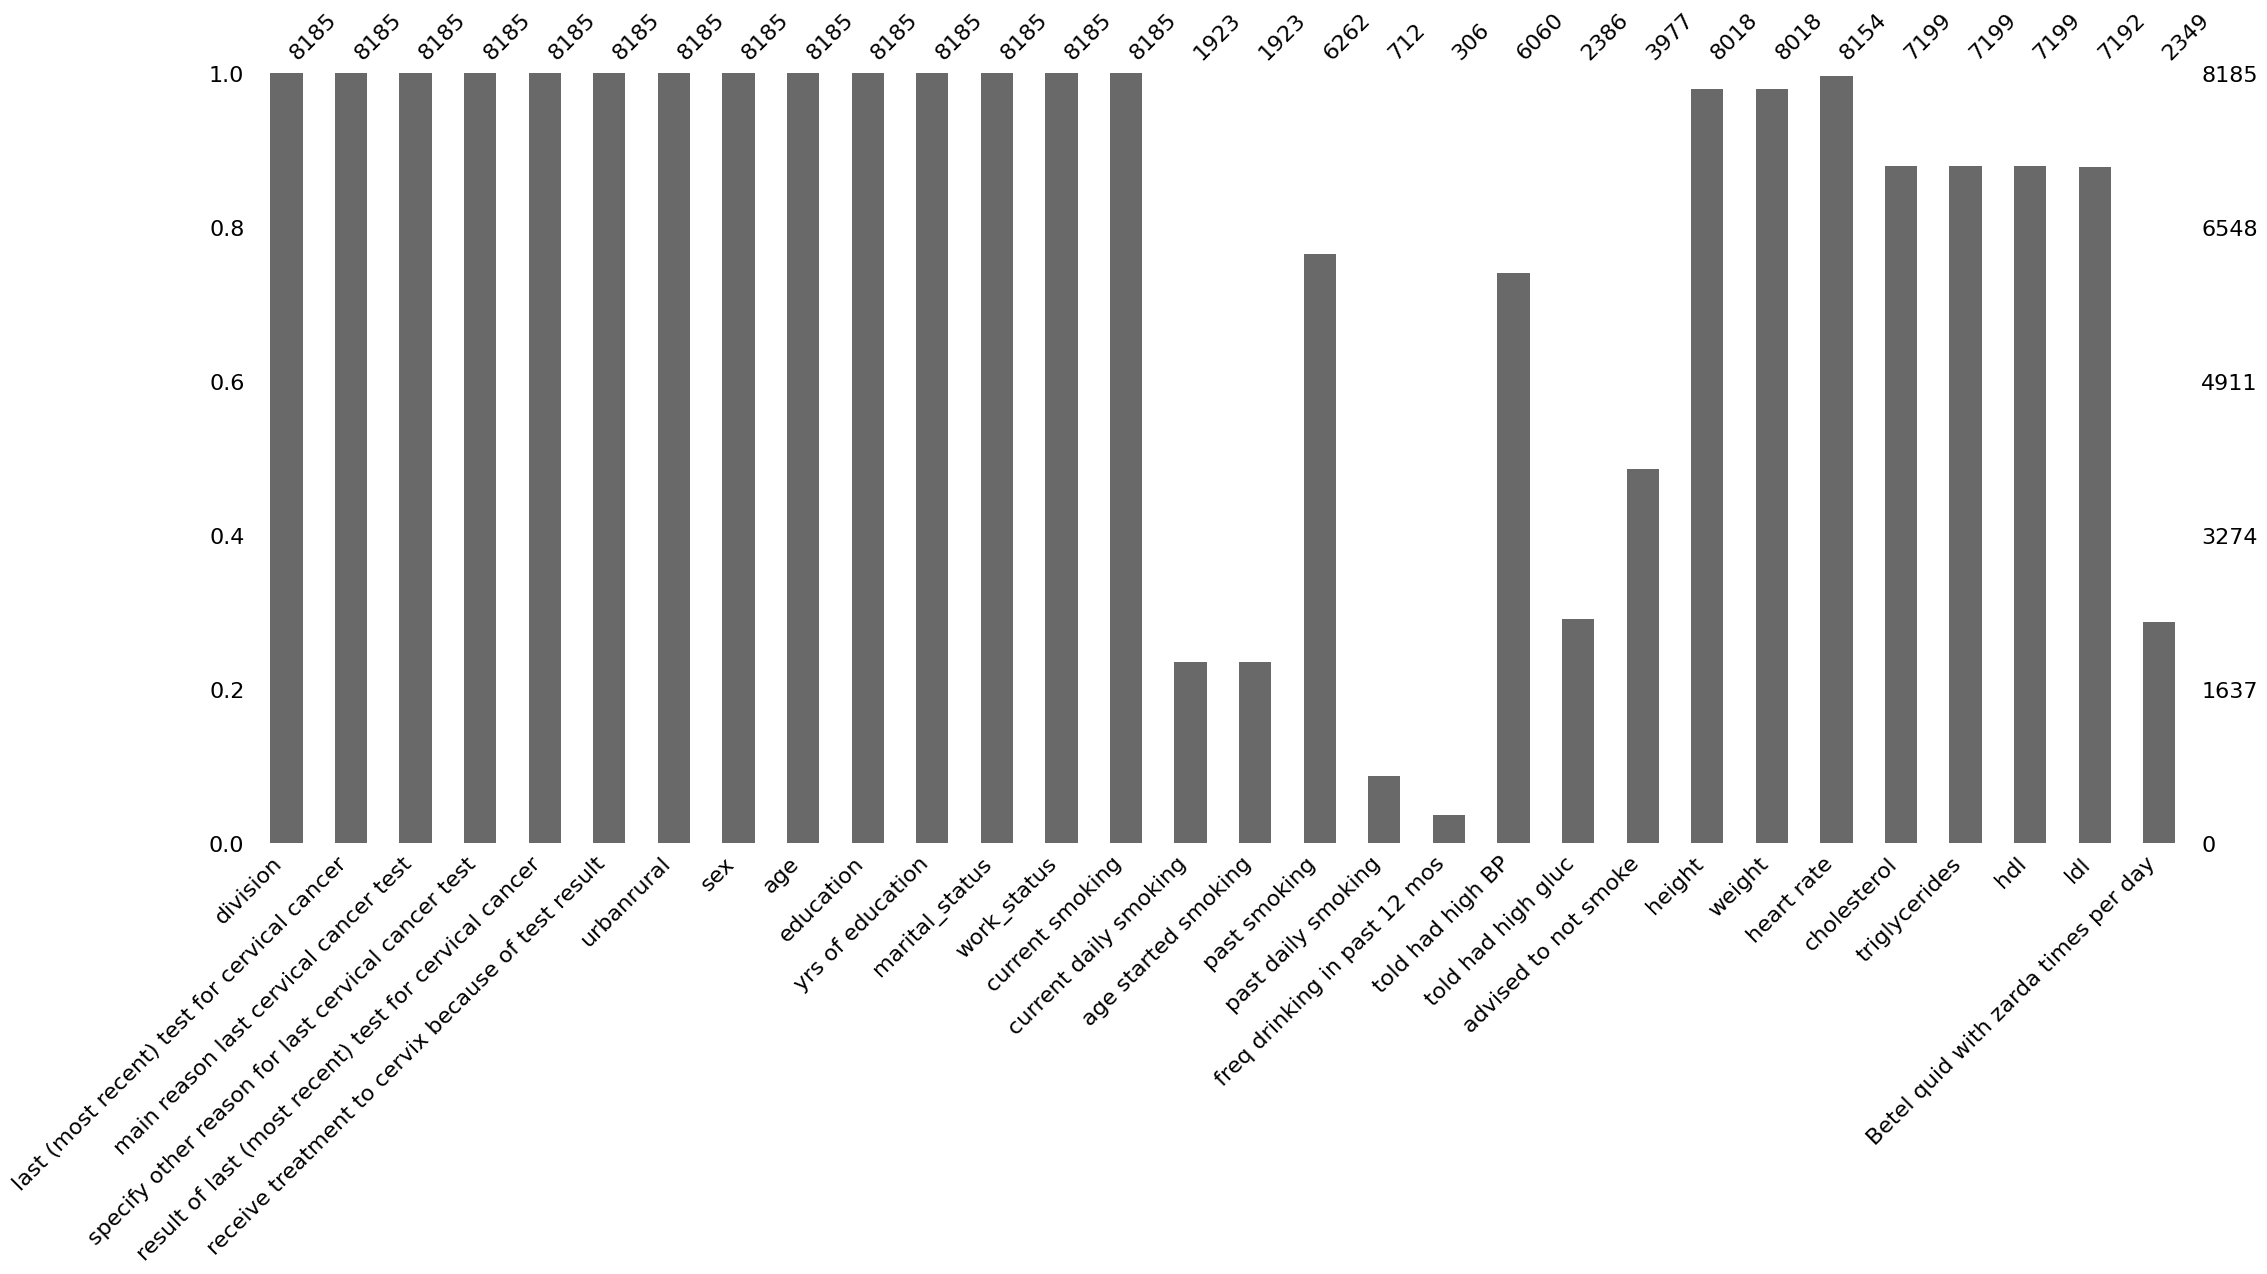

In [ ]:
msno.bar(df_ncd)
plt.show()

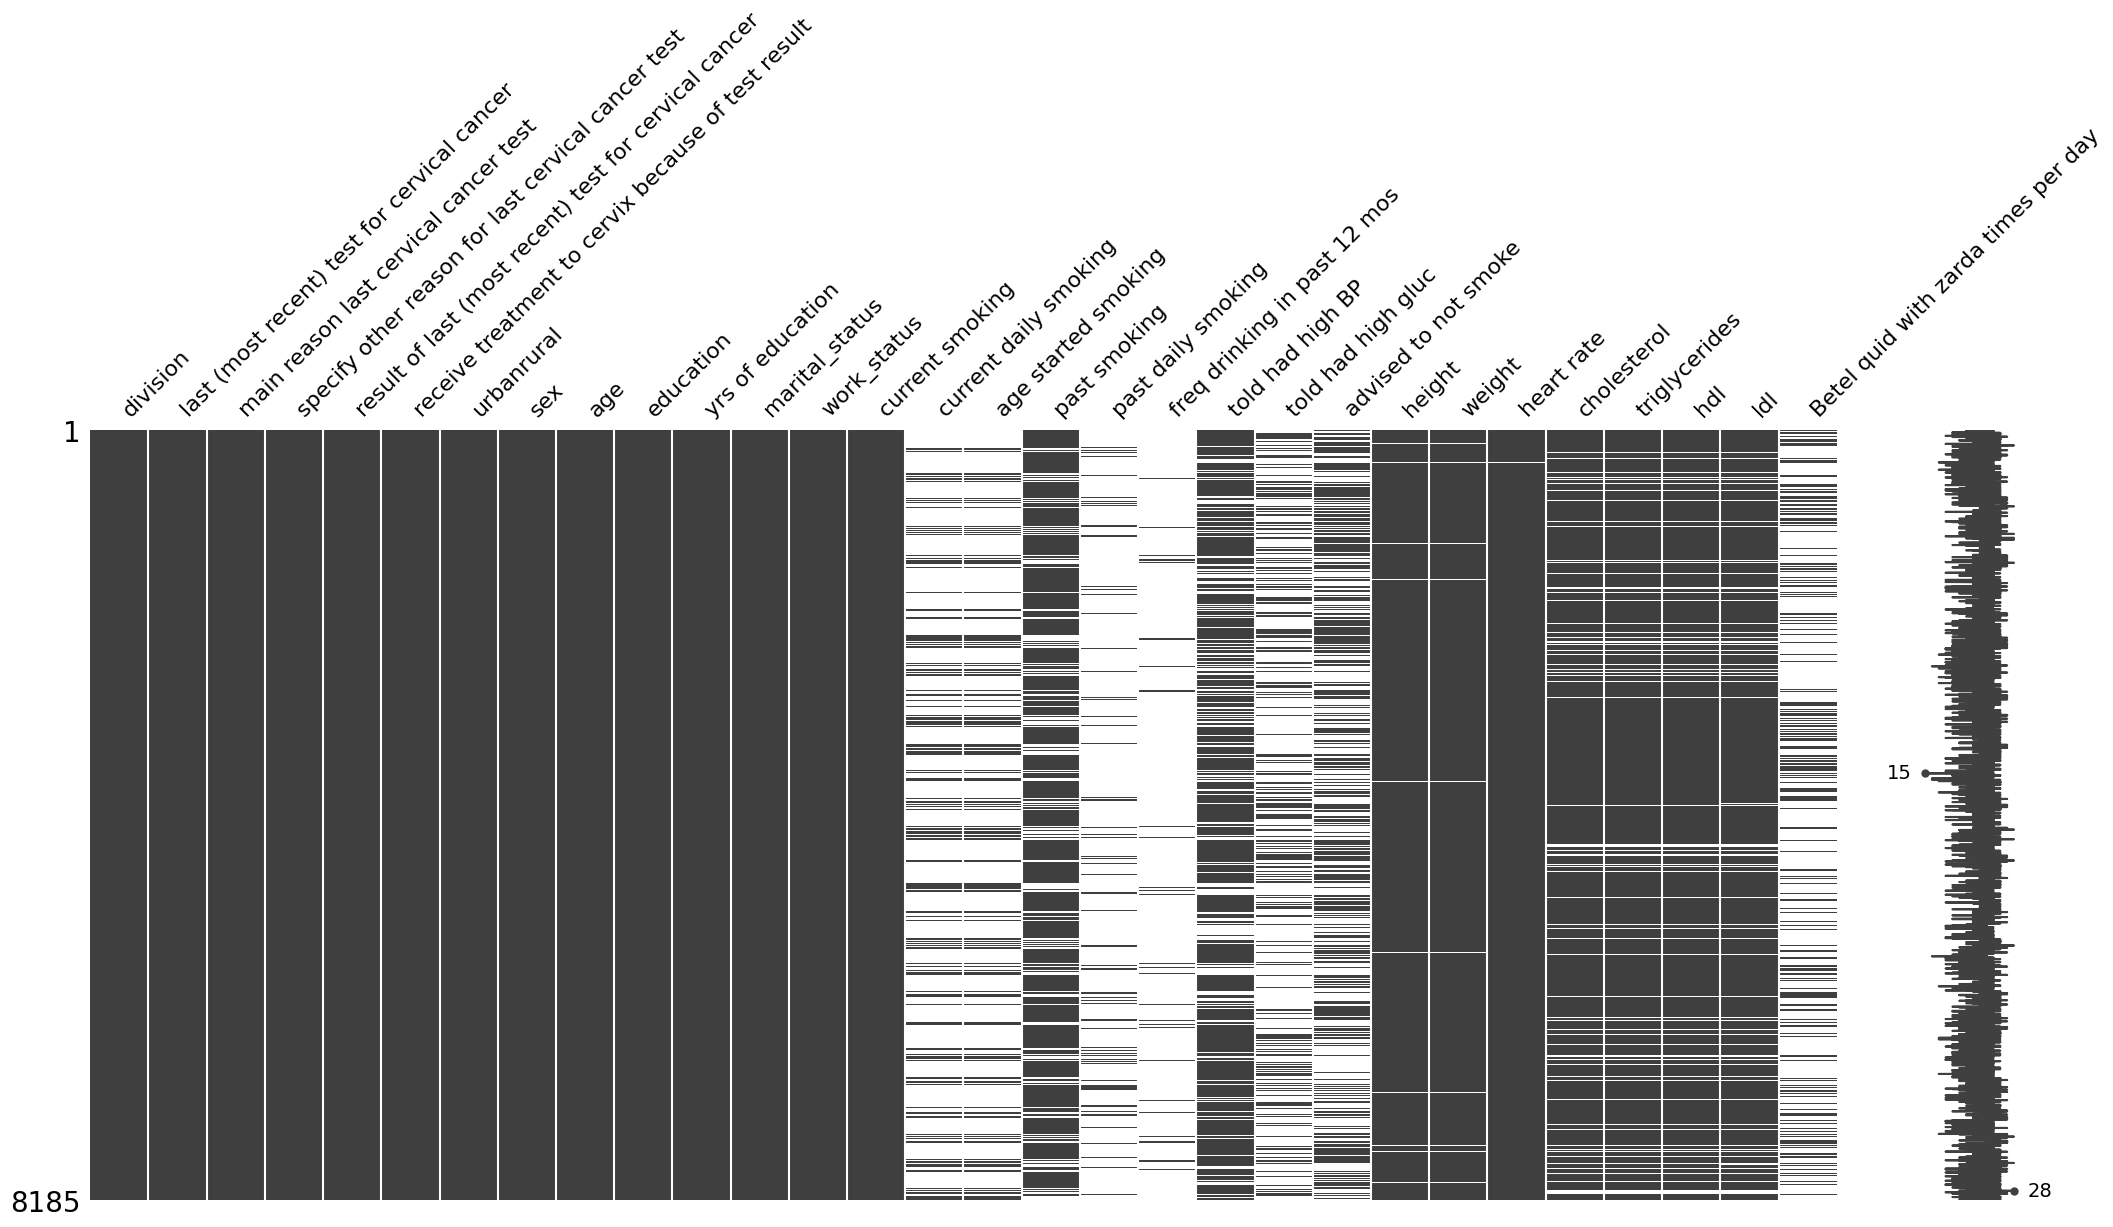

In [ ]:
msno.matrix(df_ncd)
plt.show()

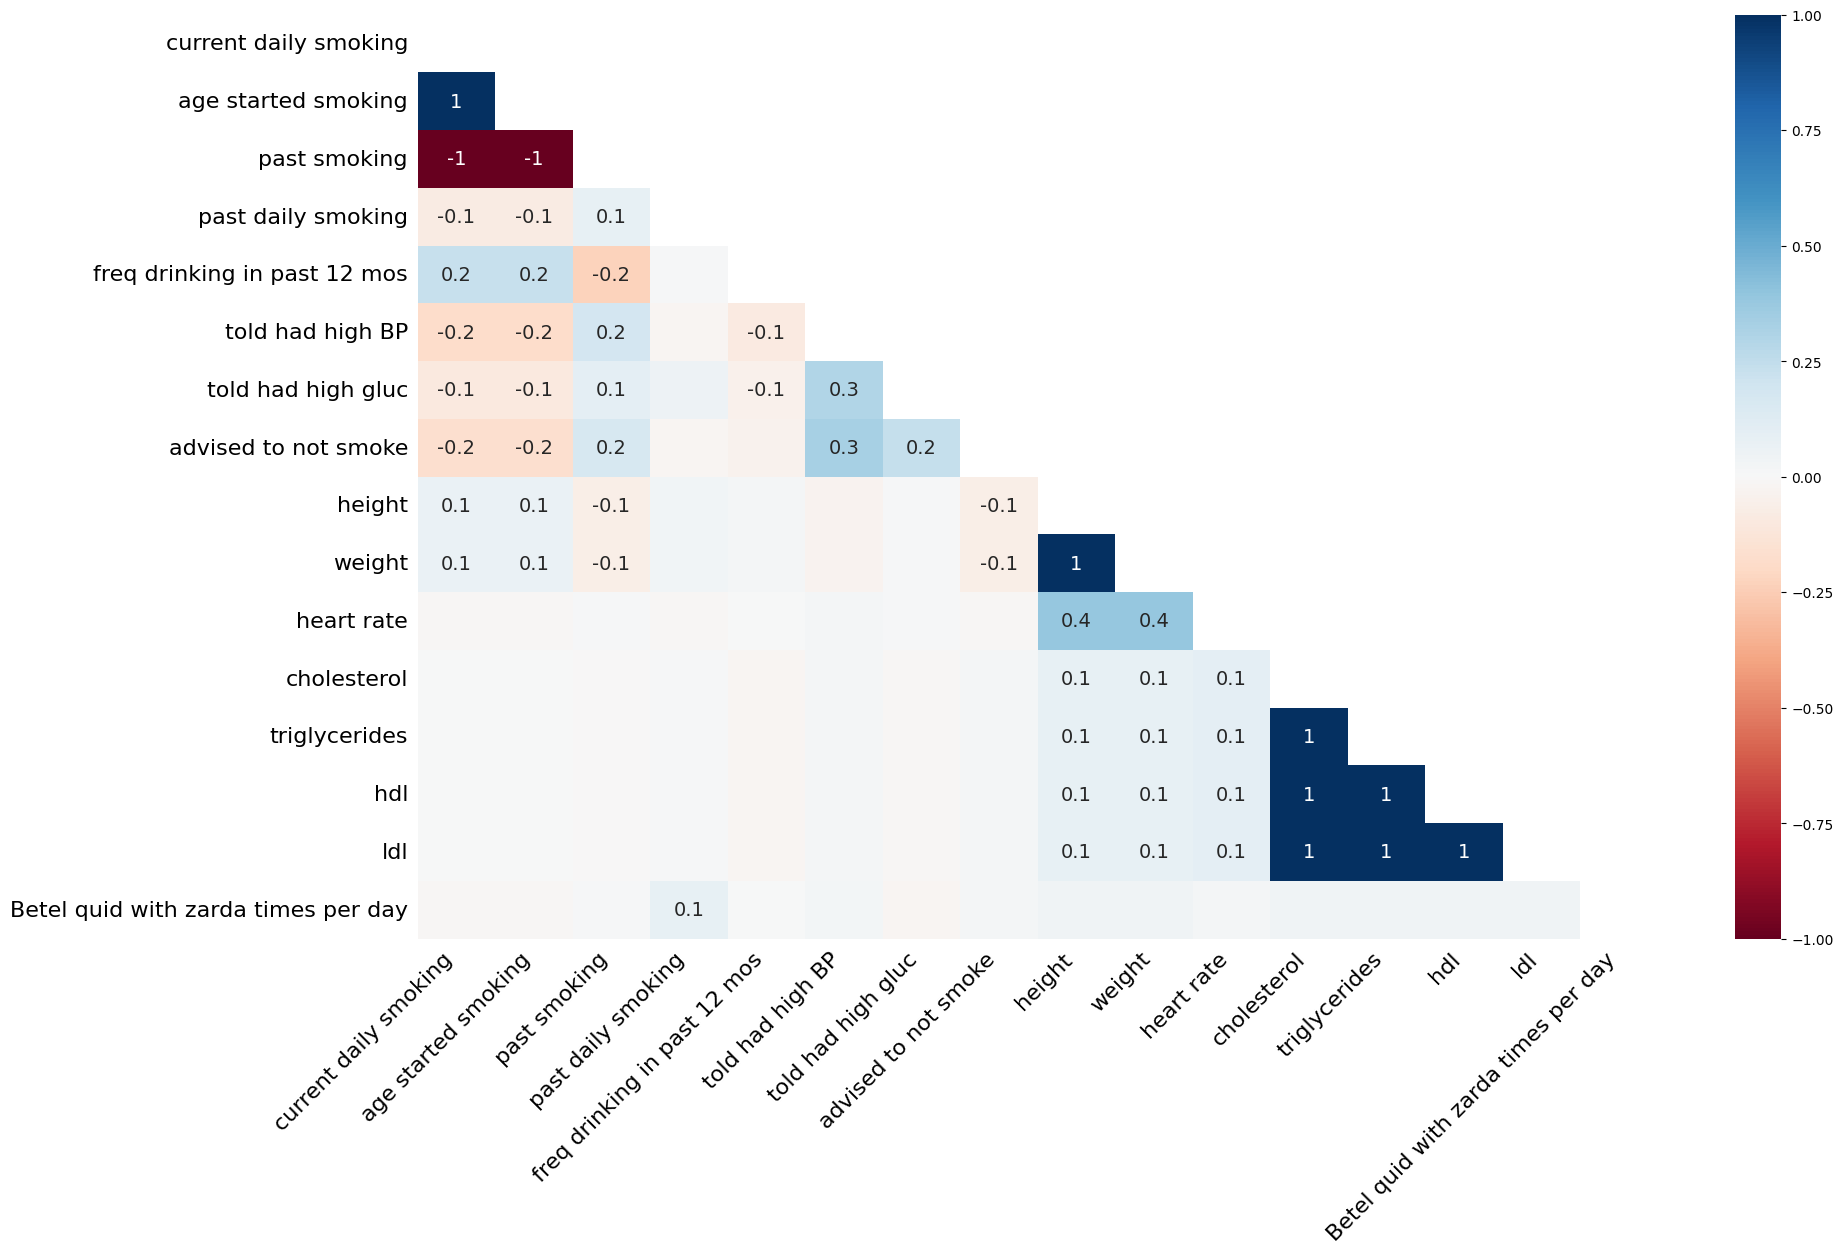

In [ ]:
msno.heatmap(df_ncd)
plt.show()

In [ ]:
# List of columns where you want to input 0 for missing values
columns_to_fill_zero = ['Betel quid with zarda times per day', 'current daily smoking', 'past smoking', 'past daily smoking', 'told had high BP', 'told had high gluc', 'advised to not smoke' ]  # Replace with your actual column names

# Fill missing values (NaN) with 0 in the specified columns
df_ncd[columns_to_fill_zero] = df_ncd[columns_to_fill_zero].fillna(0)

# Show the updated data to verify
print(df_ncd[columns_to_fill_zero].isnull().sum())  # Check if there are any remaining NaN values



Betel quid with zarda times per day    0
current daily smoking                  0
past smoking                           0
past daily smoking                     0
told had high BP                       0
told had high gluc                     0
advised to not smoke                   0
dtype: int64


In [ ]:
# List of columns where you want to replace missing values with the mean
columns_to_fill_mean = ['age started smoking', 'freq drinking in past 12 mos', 'triglycerides', 'height', 'weight', 'heart rate',
                        'cholesterol', 'hdl', 'ldl', ]

# Replace missing values with the mean for each specified column
for column in columns_to_fill_mean:
    df_ncd[column] = df_ncd[column].fillna(df_ncd[column].mean())

# Verify by checking if there are still any missing values in these columns
print(df_ncd[columns_to_fill_mean].isnull().sum())  # Should return 0 for all

age started smoking             0
freq drinking in past 12 mos    0
triglycerides                   0
height                          0
weight                          0
heart rate                      0
cholesterol                     0
hdl                             0
ldl                             0
dtype: int64


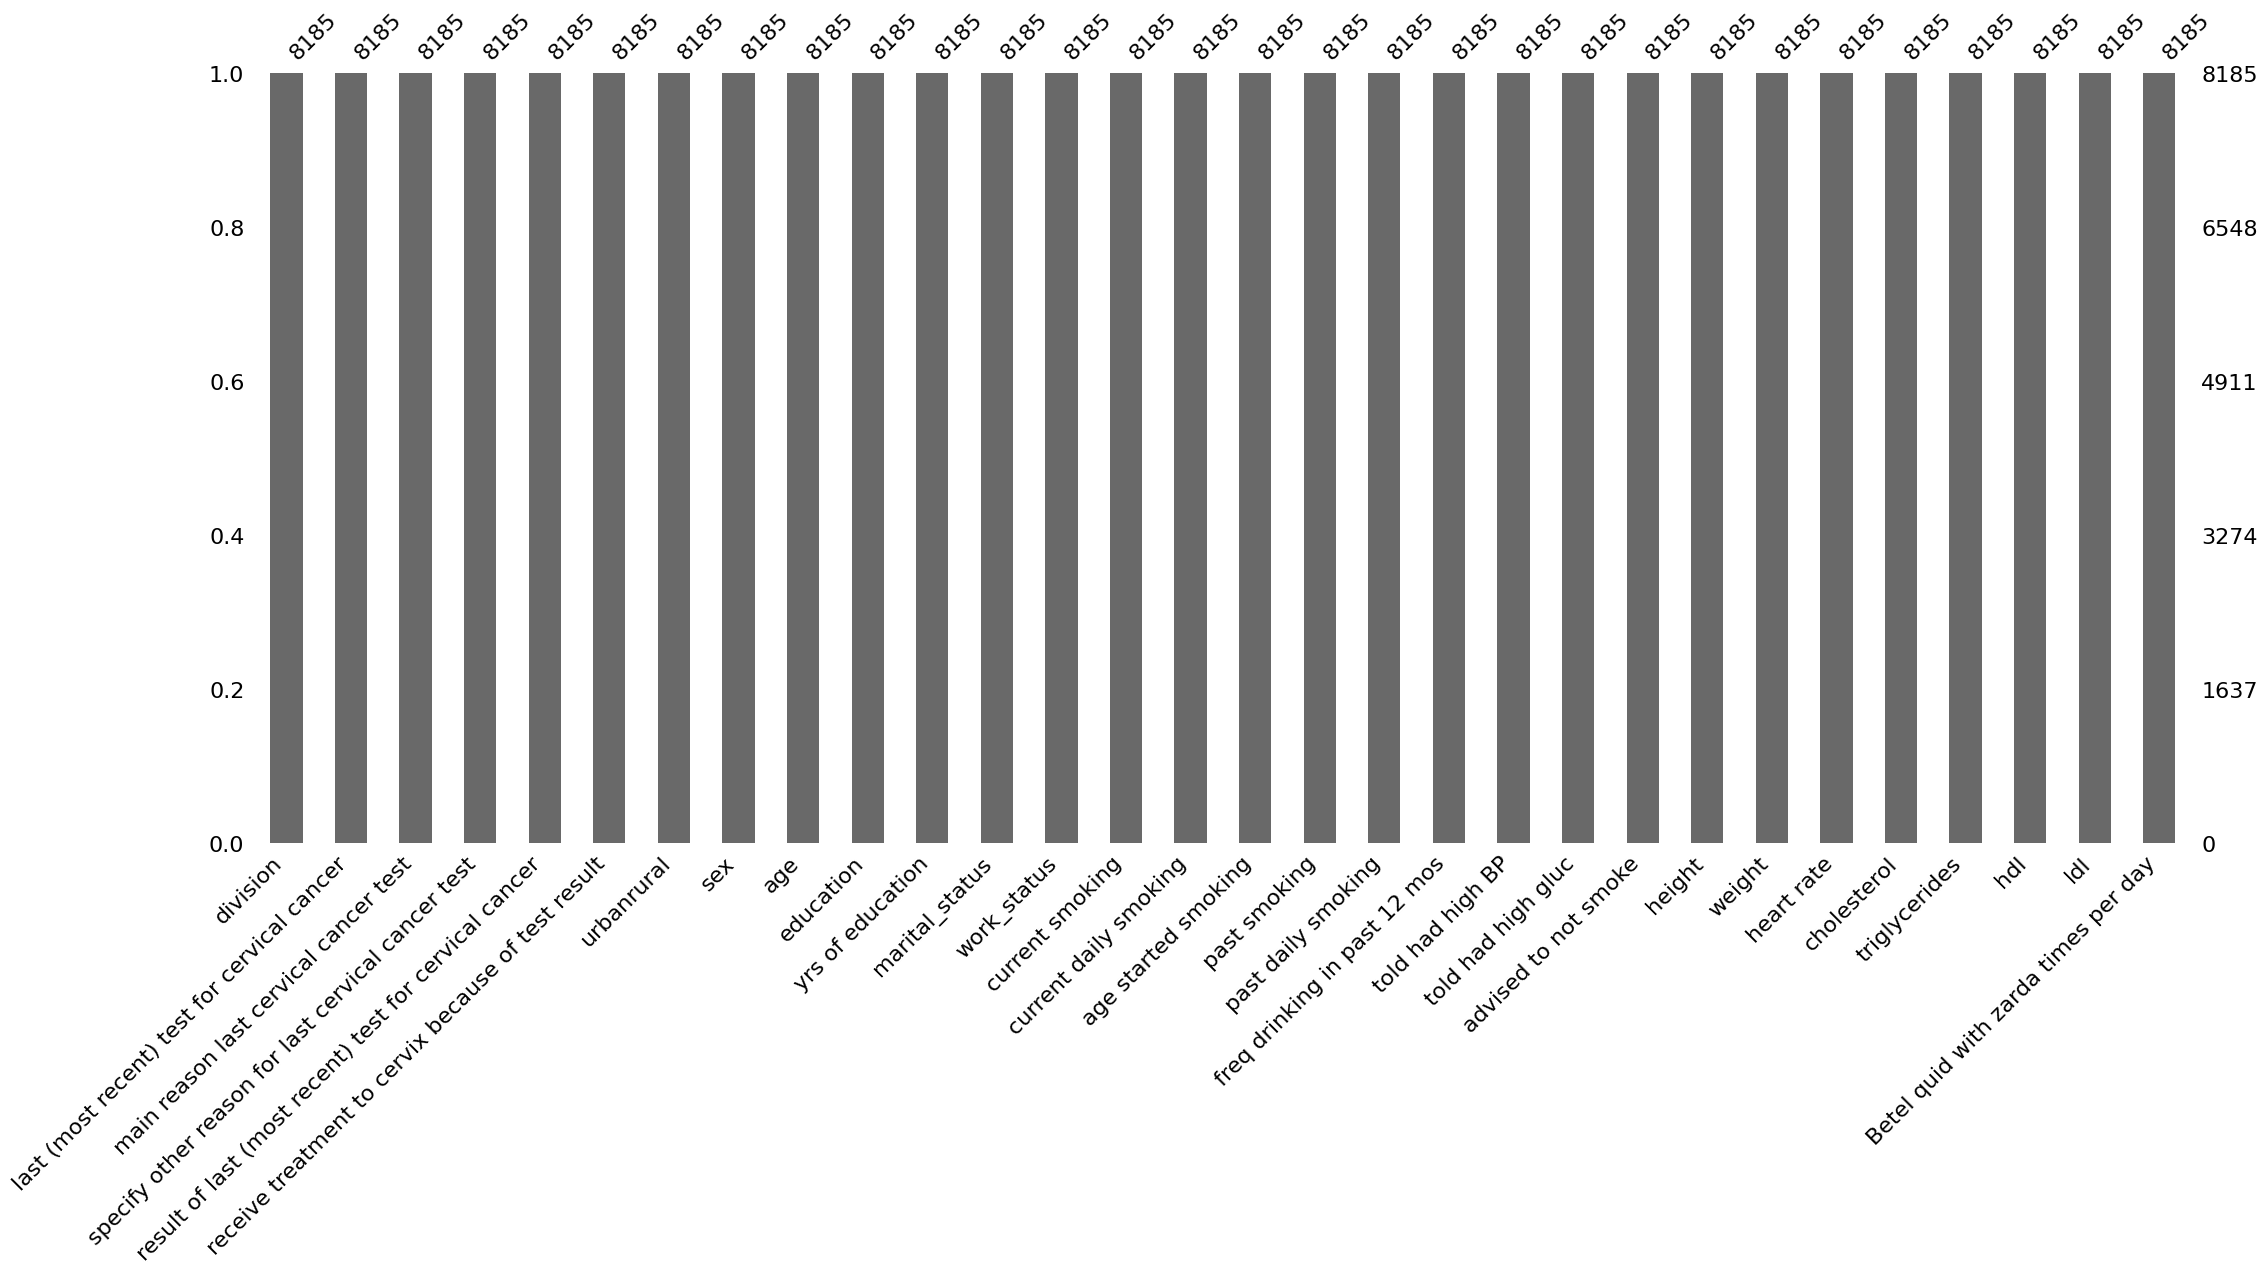

In [ ]:
msno.bar(df_ncd)
plt.show()

In [ ]:
(df_ncd.isnull().sum())*100/len(df_ncd)

,0
division,0.000
last (most recent) test for cervical cancer,0.000
main reason last cervical cancer test,0.000
specify other reason for last cervical cancer test,0.000
result of last (most recent) test for cervical cancer,0.000
receive treatment to cervix because of test result,0.000
urbanrural,0.000
sex,0.000
age,0.000
education,0.000


In [ ]:
df_ncd.duplicated().sum()

0

In [ ]:
pip install pandas seaborn matplotlib


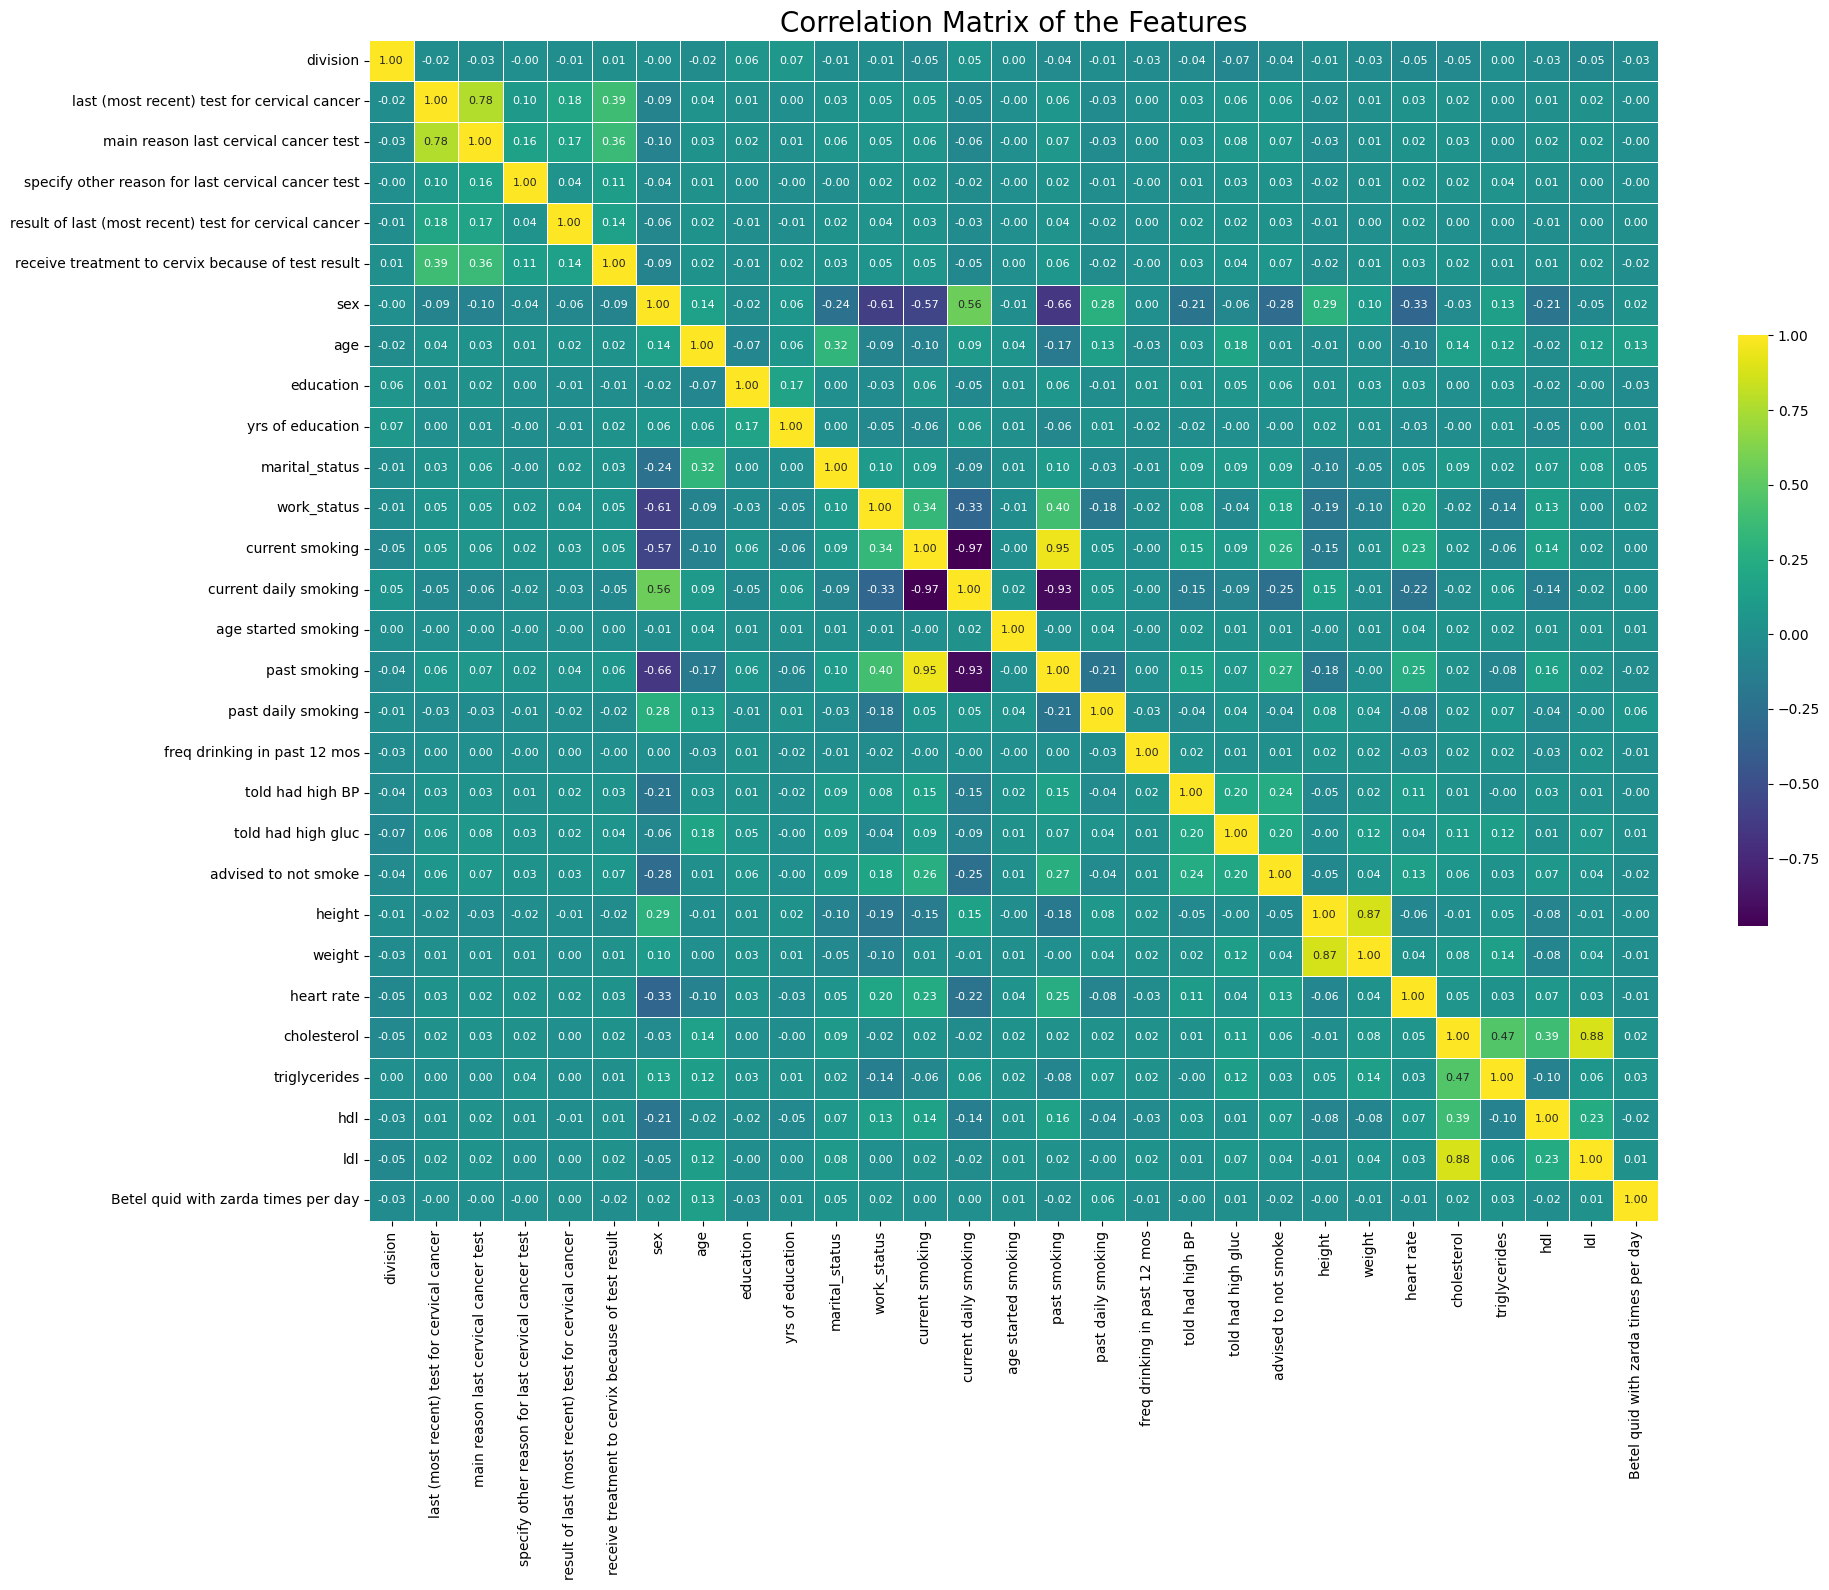

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
df = df_ncd
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(20, 16))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='viridis', linewidths=0.5, cbar_kws={'shrink': .5}, annot_kws={"size": 8})
plt.title('Correlation Matrix of the Features', fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()  # Adjust layout to ensure everything fits without overlap
plt.show()

In [ ]:
df_ncd.shape

(8185, 30)

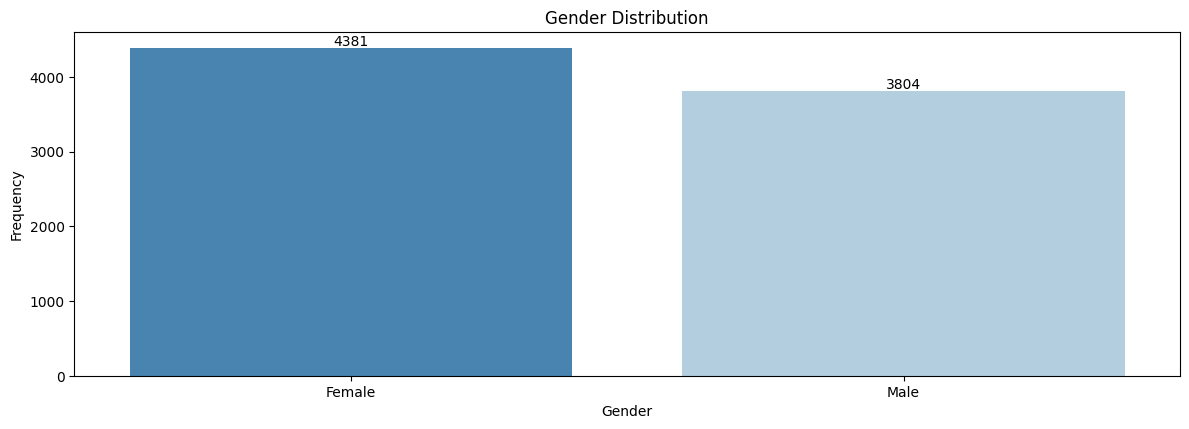

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_ncd['sex'] = df_ncd['sex'].replace({0: 'Female', 1: 'Male'})

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# Gender distribution
plt.subplot(3, 1, 1)
ax1 = sns.countplot(x='sex', data=df_ncd, palette='Blues_r')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Frequency')
annotate_barplot(ax1)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


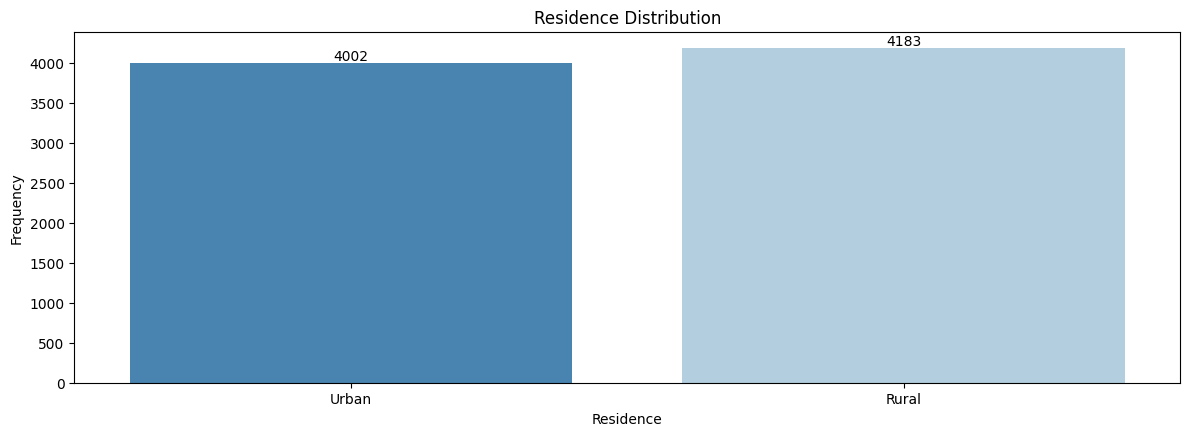

In [ ]:

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# Urban vs Rural distribution
plt.subplot(3, 1, 2)
ax2 = sns.countplot(x='urbanrural', data=df_ncd, palette='Blues_r')
plt.title('Residence Distribution')
plt.xlabel('Residence')
plt.ylabel('Frequency')
annotate_barplot(ax2)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()

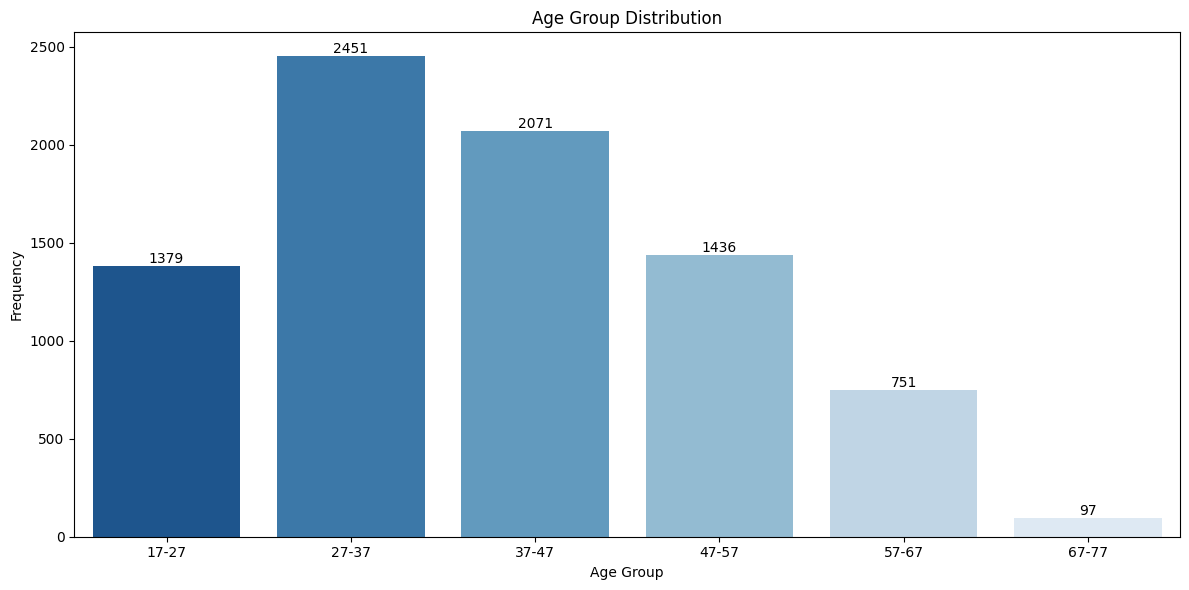

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create age bins (17-27, 27-37, etc.) and add a new 'age_group' column
age_bins = [17, 27, 37, 47, 57, 67, 77]
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for age group distribution
plt.figure(figsize=(12, 6))

# Age group distribution
ax = sns.countplot(x='age_group', data=df_ncd, palette='Blues_r')
plt.title('Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


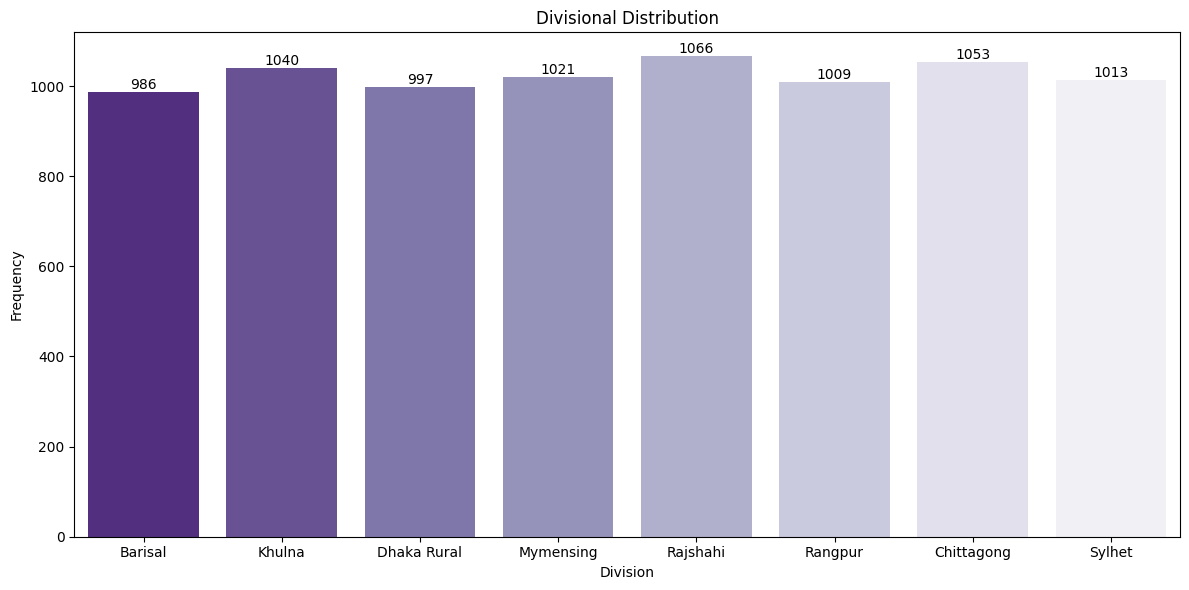

In [ ]:
# Create a dictionary for division mapping
division_mapping = {
    1: 'Barisal',
    2: 'Chittagong',
    3: 'Dhaka Rural',
    4: 'Khulna',
    5: 'Mymensing',
    6: 'Rajshahi',
    7: 'Rangpur',
    8: 'Sylhet'
}

# Assuming 'division_code' is the column in the dataset representing division
df_ncd['division'] = df_ncd['division'].map(division_mapping)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for division distribution
plt.figure(figsize=(12, 6))

# Division distribution
ax = sns.countplot(x='division', data=df_ncd, palette='Purples_r')
plt.title('Divisional Distribution')
plt.xlabel('Division')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 31 columns):
 #   Column                                                 Non-Null Count  Dtype   
---  ------                                                 --------------  -----   
 0   division                                               8185 non-null   object  
 1   last (most recent) test for cervical cancer            8185 non-null   float64 
 2   main reason last cervical cancer test                  8185 non-null   float64 
 3   specify other reason for last cervical cancer test     8185 non-null   float64 
 4   result of last (most recent) test for cervical cancer  8185 non-null   float64 
 5   receive treatment to cervix because of test result     8185 non-null   float64 
 6   urbanrural                                             8185 non-null   object  
 7   sex                                                    8185 non-null   object  
 8   age                                   

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


# Define the features and safe ranges
features = [
    'last (most recent) test for cervical cancer',
    'main reason last cervical cancer test',
    'specify other reason for last cervical cancer test',
    'result of last (most recent) test for cervical cancer',
    'receive treatment to cervix because of test result',
    'current smoking', 'current daily smoking', 'age started smoking',
    'past smoking', 'past daily smoking', 'freq drinking in past 12 mos',
    'told had high BP', 'told had high gluc', 'advised to not smoke', 'Betel quid with zarda times per day', 'age',
    'height', 'weight', 'heart rate', 'cholesterol', 'triglycerides', 'hdl', 'ldl'
]

safe_ranges = {
    'last (most recent) test for cervical cancer': (0, 0),
    'main reason last cervical cancer test': (0, 0),
    'result of last (most recent) test for cervical cancer': (0, 0),
    'receive treatment to cervix because of test result': (0, 0),
    'specify other reason for last cervical cancer test' : (0, 0),
    'heart rate': (60, 80),
    'cholesterol': (0, 200),
    'triglycerides': (50, 150),

}

# Function to calculate risk based on safe ranges
def calculate_risk(row):
    risk = 0
    for feature, (low, high) in safe_ranges.items():
        if low <= row[feature] <= high:
            risk += 0  # Low risk, within range
        else:
            risk += 1  # Increment risk for out-of-range values
    return risk

# Ensure all required features are in the dataset
missing_features = [col for col in features if col not in df_ncd.columns]
if missing_features:
    raise ValueError(f"The following features are missing from the dataset: {missing_features}")

# Apply risk calculation to the dataset
df_ncd['risk_score'] = df_ncd.apply(calculate_risk, axis=1)

# Binary feature adjustments: Map binary values to reflect risk directly
binary_features = ['told had high gluc', 'advised to not smoke']

# Ensure binary features are in the dataset
missing_binary_features = [col for col in binary_features if col not in df_ncd.columns]
if missing_binary_features:
    raise ValueError(f"The following binary features are missing: {missing_binary_features}")

# Map binary values: 1 for high risk, -1 for protective (if applicable), 0 for neutral
df_ncd[binary_features] = df_ncd[binary_features].replace({2: -1, 1: 1, 0: 0})

# Combine risk scores with binary features for clustering
selected_features = list(safe_ranges.keys()) + binary_features + ['risk_score']

# Check and handle missing values
if df_ncd[selected_features].isnull().any().any():
    print("Handling missing values...")
    df_ncd[selected_features] = df_ncd[selected_features].fillna(0)

# Ensure all features are numeric
df_ncd[selected_features] = df_ncd[selected_features].apply(pd.to_numeric, errors='coerce')

# Verify that no NaN values remain
if df_ncd[selected_features].isnull().any().any():
    raise ValueError("NaN values remain in the dataset after handling missing values.")

# Scale features for clustering
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_ncd[selected_features])

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df_ncd['Risk of cancer'] = kmeans.fit_predict(df_scaled)

# Map the clusters to risk categories
cluster_centers = kmeans.cluster_centers_
cluster_risk_scores = cluster_centers[:, selected_features.index('risk_score')]
risk_mapping = dict(zip(np.argsort(cluster_risk_scores), ['Low', 'Medium', 'High']))
df_ncd['Risk of cancer'] = df_ncd['Risk of cancer'].map(risk_mapping)

# Output the results
print("Clustering complete. Here is the distribution of risk categories:")
print(df_ncd['Risk of cancer'].value_counts())
print("First few rows with risk categories:")
print(df_ncd[['Risk of cancer'] + selected_features].head())



Clustering complete. Here is the distribution of risk categories:
Risk of cancer
Low       5907
Medium    2178
High       100
Name: count, dtype: int64
First few rows with risk categories:
  Risk of cancer  last (most recent) test for cervical cancer  \
0            Low                                        0.000   
1            Low                                        0.000   
2            Low                                        0.000   
3            Low                                        0.000   
4         Medium                                        0.000   

   main reason last cervical cancer test  \
0                                  0.000   
1                                  0.000   
2                                  0.000   
3                                  0.000   
4                                  0.000   

   result of last (most recent) test for cervical cancer  \
0                                              0.000       
1                                  

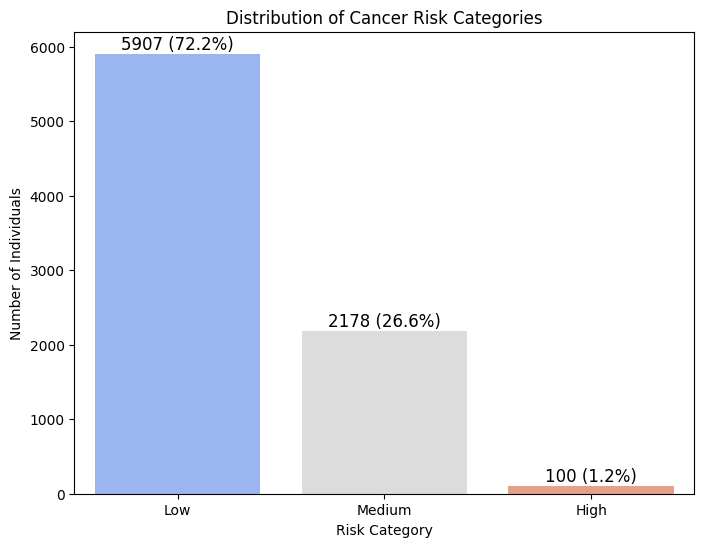

In [ ]:
# Import necessary libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category and calculate percentages
risk_counts = df_ncd['Risk of cancer'].value_counts()
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Set up the plot
plt.figure(figsize=(8, 6))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette="coolwarm")

# Add titles and labels
plt.title("Distribution of Cancer Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Individuals")

# Add percentage and count labels on top of each bar
for i, (count, pct) in enumerate(zip(risk_counts.values, risk_percentages.values)):
    plt.text(i, count + 10, f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=12)

plt.xticks(rotation=0)
plt.show()



In [ ]:
# Separate data into High, Medium, and Low risk categories
high_risk = df_ncd[df_ncd['Risk of cancer'] == 'High']
medium_risk = df_ncd[df_ncd['Risk of cancer'] == 'Medium']
low_risk = df_ncd[df_ncd['Risk of cancer'] == 'Low']

# Calculate descriptive statistics for each risk category
high_risk_stats = high_risk[features].describe()
medium_risk_stats = medium_risk[features].describe()
low_risk_stats = low_risk[features].describe()

# Display the statistics for each risk category
print("High Risk Category Statistics:")
print(high_risk_stats)

print("\nMedium Risk Category Statistics:")
print(medium_risk_stats)

print("\nLow Risk Category Statistics:")
print(low_risk_stats)


High Risk Category Statistics:
       last (most recent) test for cervical cancer  \
count                                      100.000   
mean                                         3.540   
std                                          7.504   
min                                          1.000   
25%                                          2.000   
50%                                          3.000   
75%                                          4.000   
max                                         77.000   

       main reason last cervical cancer test  \
count                                100.000   
mean                                   5.720   
std                                   10.306   
min                                    1.000   
25%                                    3.000   
50%                                    5.000   
75%                                    5.000   
max                                   77.000   

       specify other reason for last cervical can

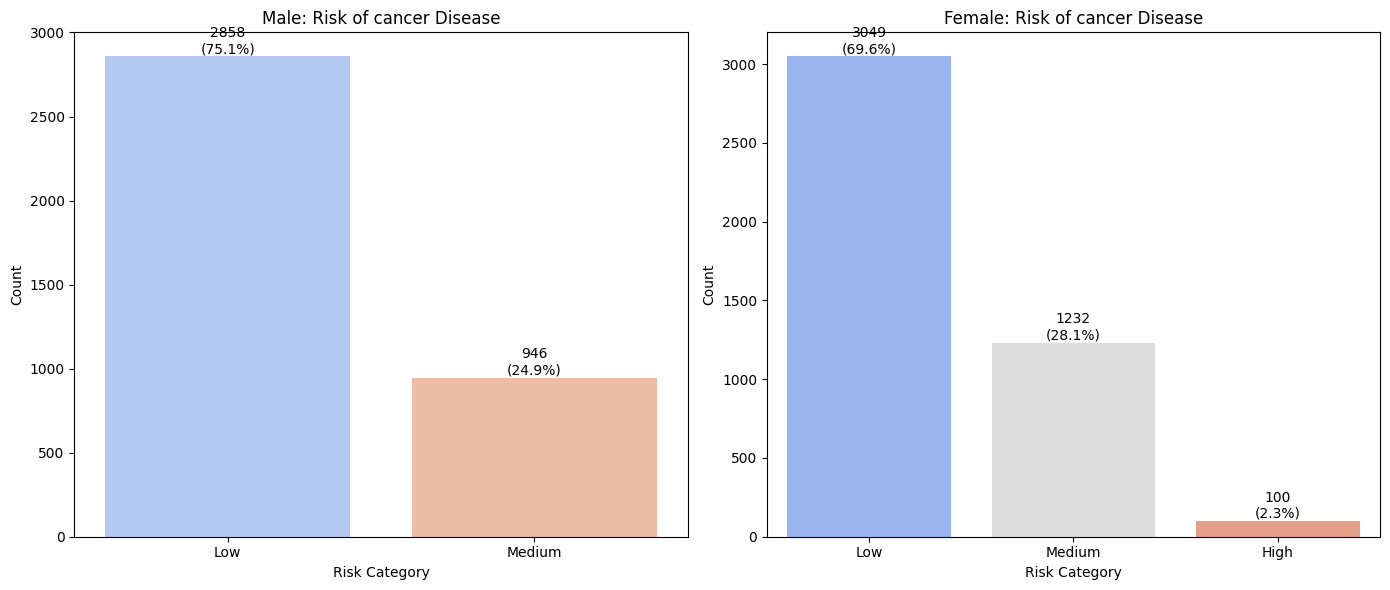

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

male_data = df_ncd[df_ncd['sex'] == 'Male']
female_data = df_ncd[df_ncd['sex'] == 'Female']

# Calculate counts and percentages for each category
male_counts = male_data['Risk of cancer'].value_counts()
male_percentages = male_data['Risk of cancer'].value_counts(normalize=True) * 100

female_counts = female_data['Risk of cancer'].value_counts()
female_percentages = female_data['Risk of cancer'].value_counts(normalize=True) * 100

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Male Risk of cancer (Counts and Percentages)
sns.barplot(x=male_counts.index, y=male_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Male: Risk of cancer Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for males
for i, count in enumerate(male_counts):
    axes[0].text(i, count + 1, f'{count}\n({male_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Female Risk of cancer (Counts and Percentages)
sns.barplot(x=female_counts.index, y=female_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Female: Risk of cancer Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for females
for i, count in enumerate(female_counts):
    axes[1].text(i, count + 1, f'{count}\n({female_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


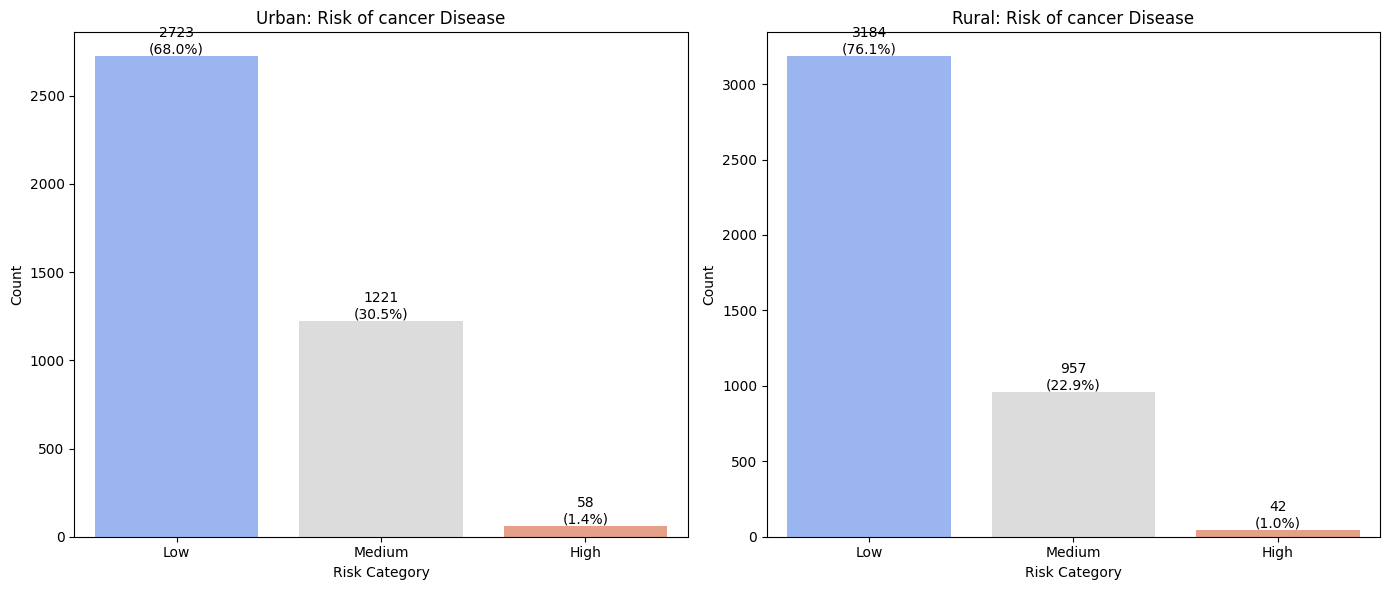

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate data for urban and rural categories
urban_data = df_ncd[df_ncd['urbanrural'] == 'Urban']  # or df_ncd['urbanrural'] == 1
rural_data = df_ncd[df_ncd['urbanrural'] == 'Rural']  # or df_ncd['urbanrural'] == 2

# Calculate counts and percentages for each category
urban_counts = urban_data['Risk of cancer'].value_counts()
urban_percentages = urban_data['Risk of cancer'].value_counts(normalize=True) * 100

rural_counts = rural_data['Risk of cancer'].value_counts()
rural_percentages = rural_data['Risk of cancer'].value_counts(normalize=True) * 100

# Plotting counts and percentages for each risk category in Urban and Rural
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Urban Risk of cancer (Counts and Percentages)
sns.barplot(x=urban_counts.index, y=urban_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Urban: Risk of cancer Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for Urban data
for i, count in enumerate(urban_counts):
    percentage = urban_percentages[i]
    axes[0].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Rural Risk of cancer (Counts and Percentages)
sns.barplot(x=rural_counts.index, y=rural_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Rural: Risk of cancer Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for Rural data
for i, count in enumerate(rural_counts):
    percentage = rural_percentages[i]
    axes[1].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


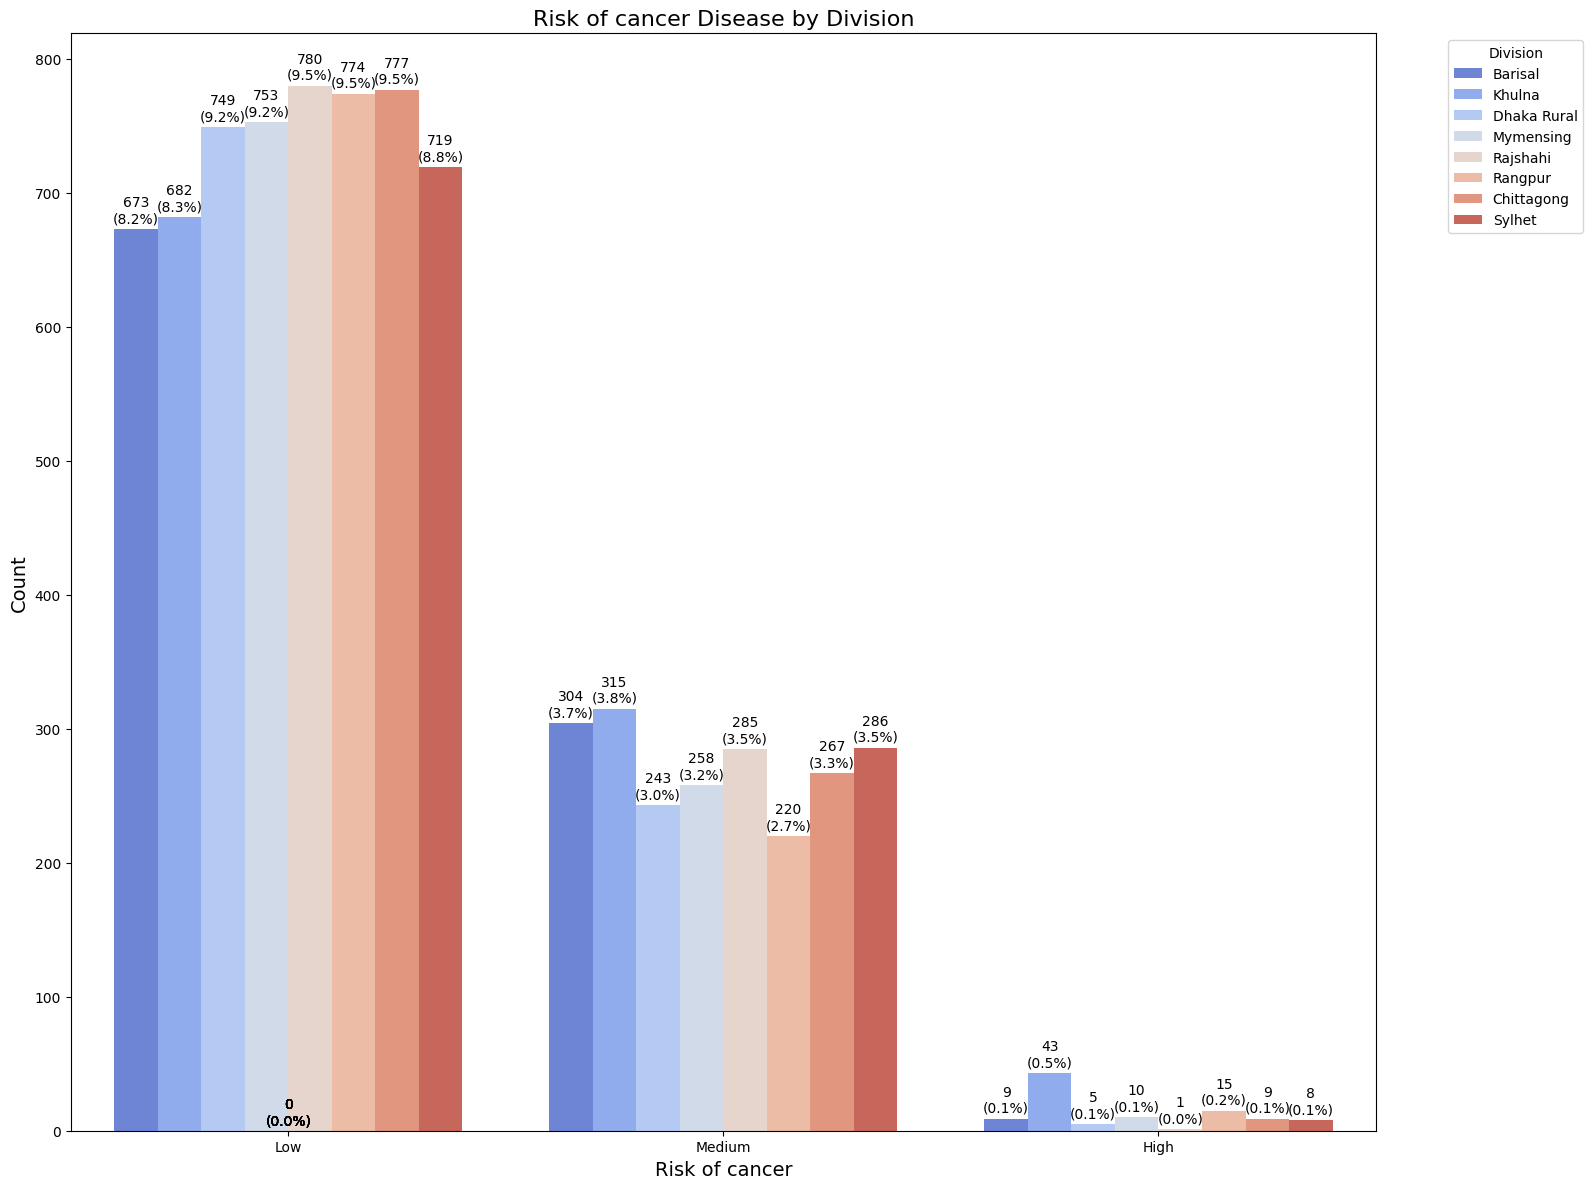

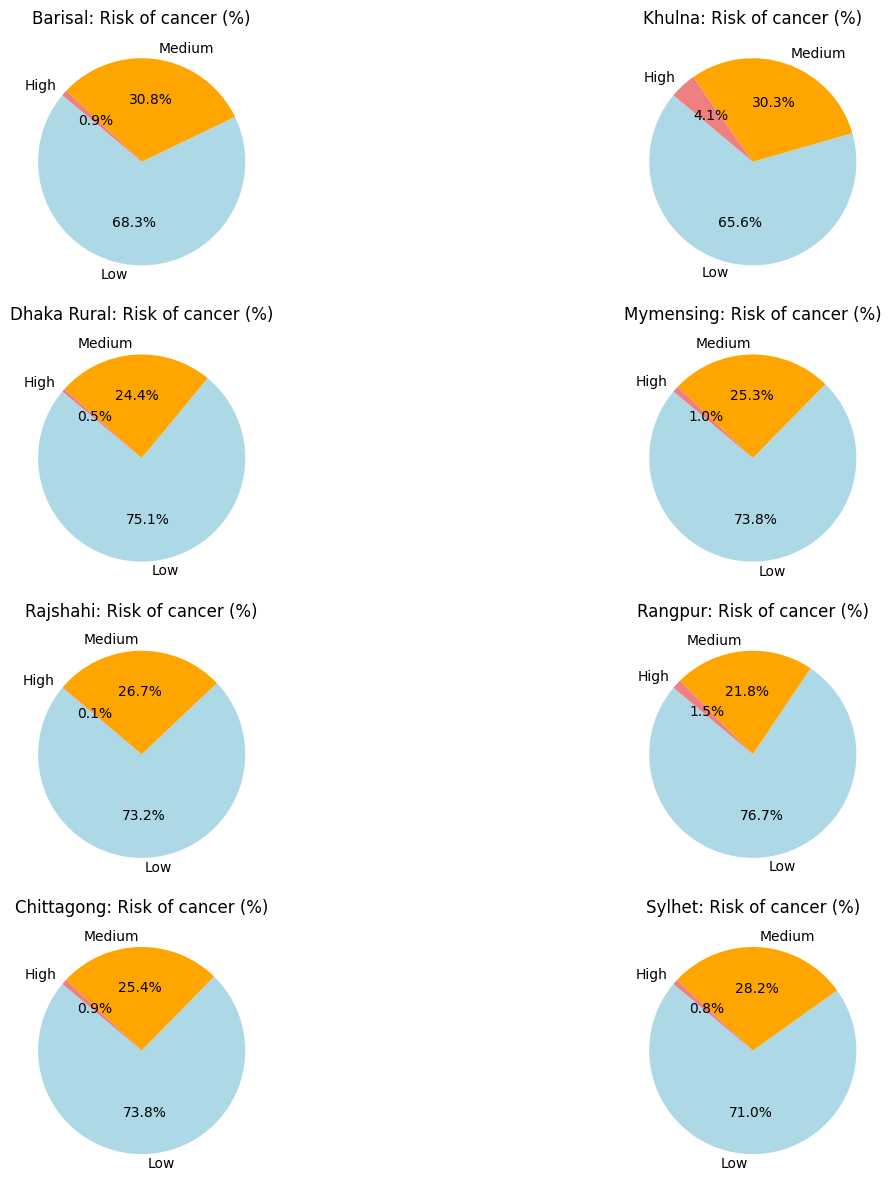

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across divisions
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of cancer', hue='division', data=df_ncd, palette='coolwarm')
plt.title('Risk of cancer Disease by Division', fontsize=16)
plt.xlabel('Risk of cancer', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Division', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each division
divisions = df_ncd['division'].unique()
num_divisions = len(divisions)
plt.figure(figsize=(16, 12))

for idx, division in enumerate(divisions, 1):
    division_data = df_ncd[df_ncd['division'] == division]
    division_counts = division_data['Risk of cancer'].value_counts()

    plt.subplot((num_divisions + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(division_counts, labels=division_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{division}: Risk of cancer (%)')

plt.tight_layout()
plt.show()


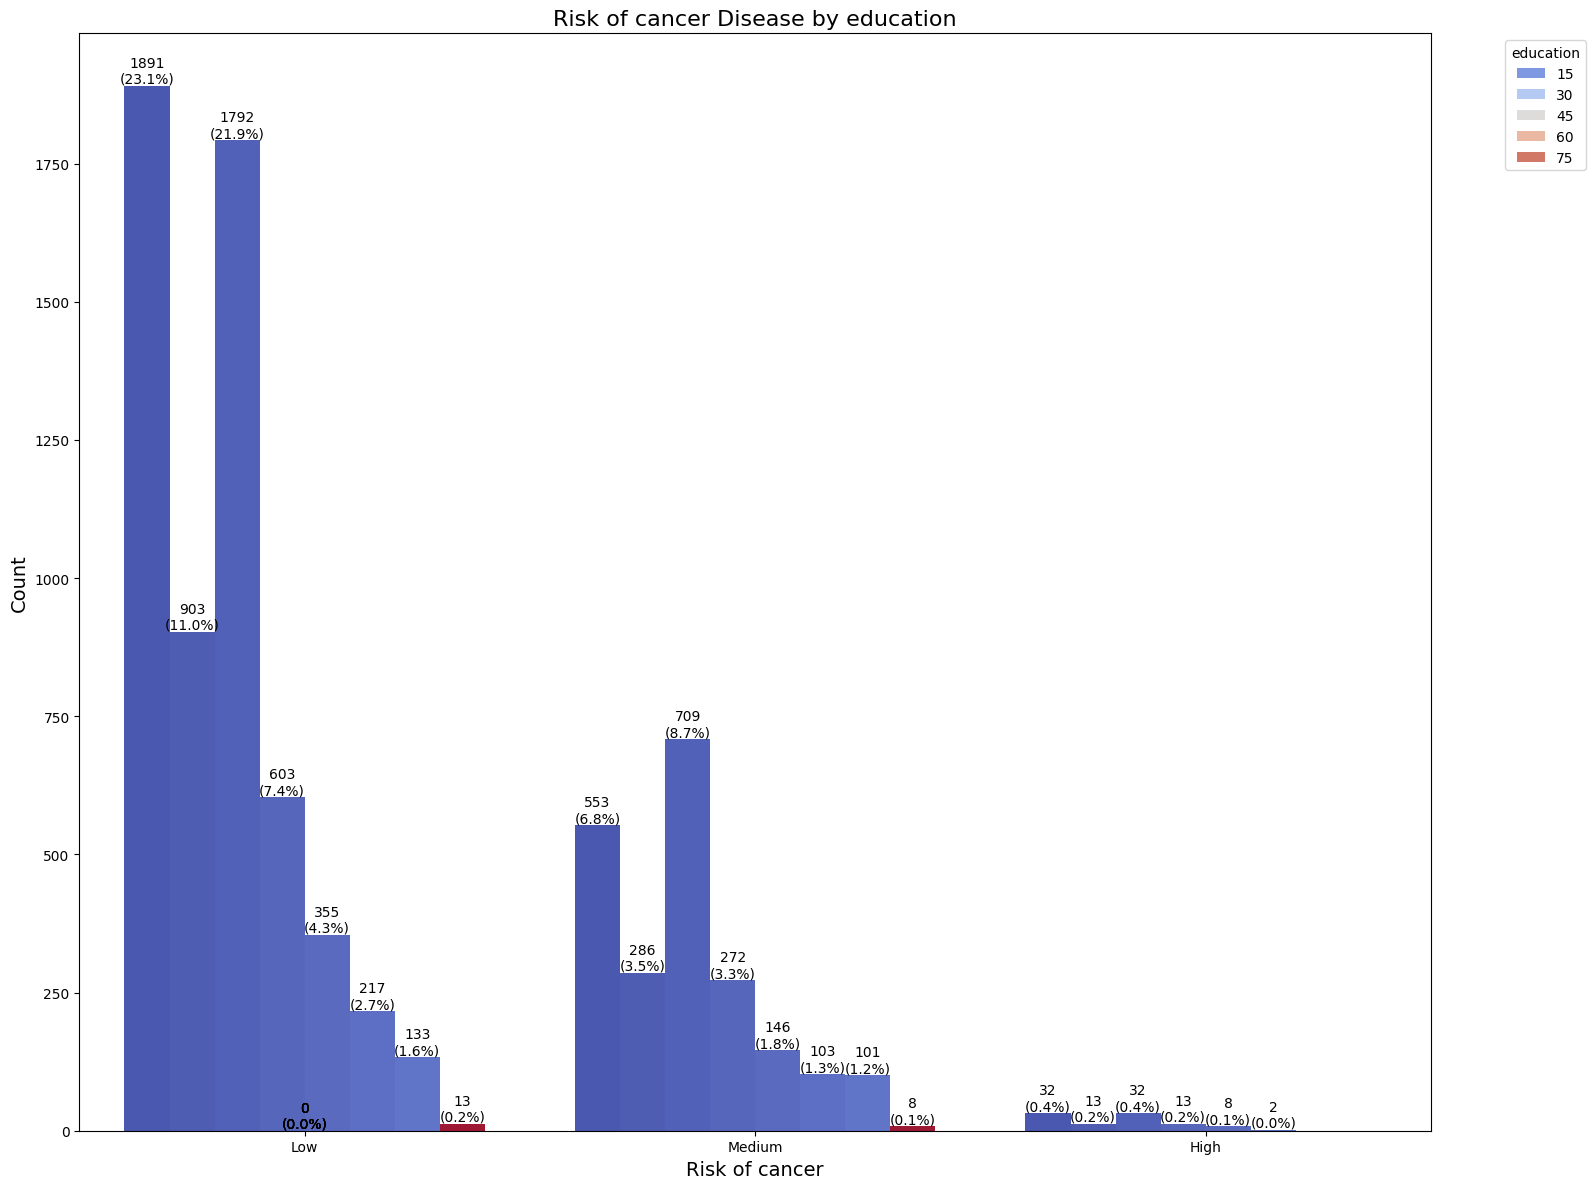

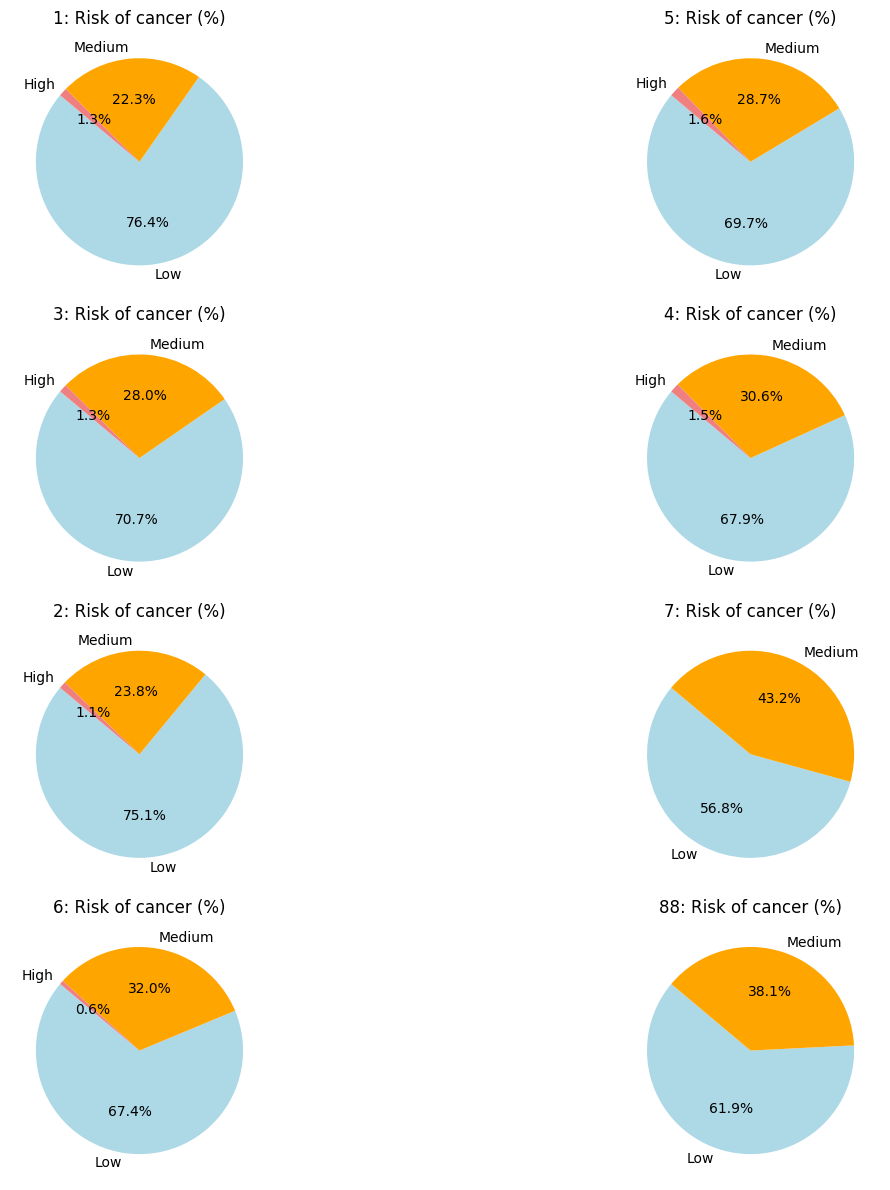

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across educations
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of cancer', hue='education', data=df_ncd, palette='coolwarm')
plt.title('Risk of cancer Disease by education', fontsize=16)
plt.xlabel('Risk of cancer', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='education', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each education
educations = df_ncd['education'].unique()
num_educations = len(educations)
plt.figure(figsize=(16, 12))

for idx, education in enumerate(educations, 1):
    education_data = df_ncd[df_ncd['education'] == education]
    education_counts = education_data['Risk of cancer'].value_counts()

    plt.subplot((num_educations + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(education_counts, labels=education_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{education}: Risk of cancer (%)')

plt.tight_layout()
plt.show()


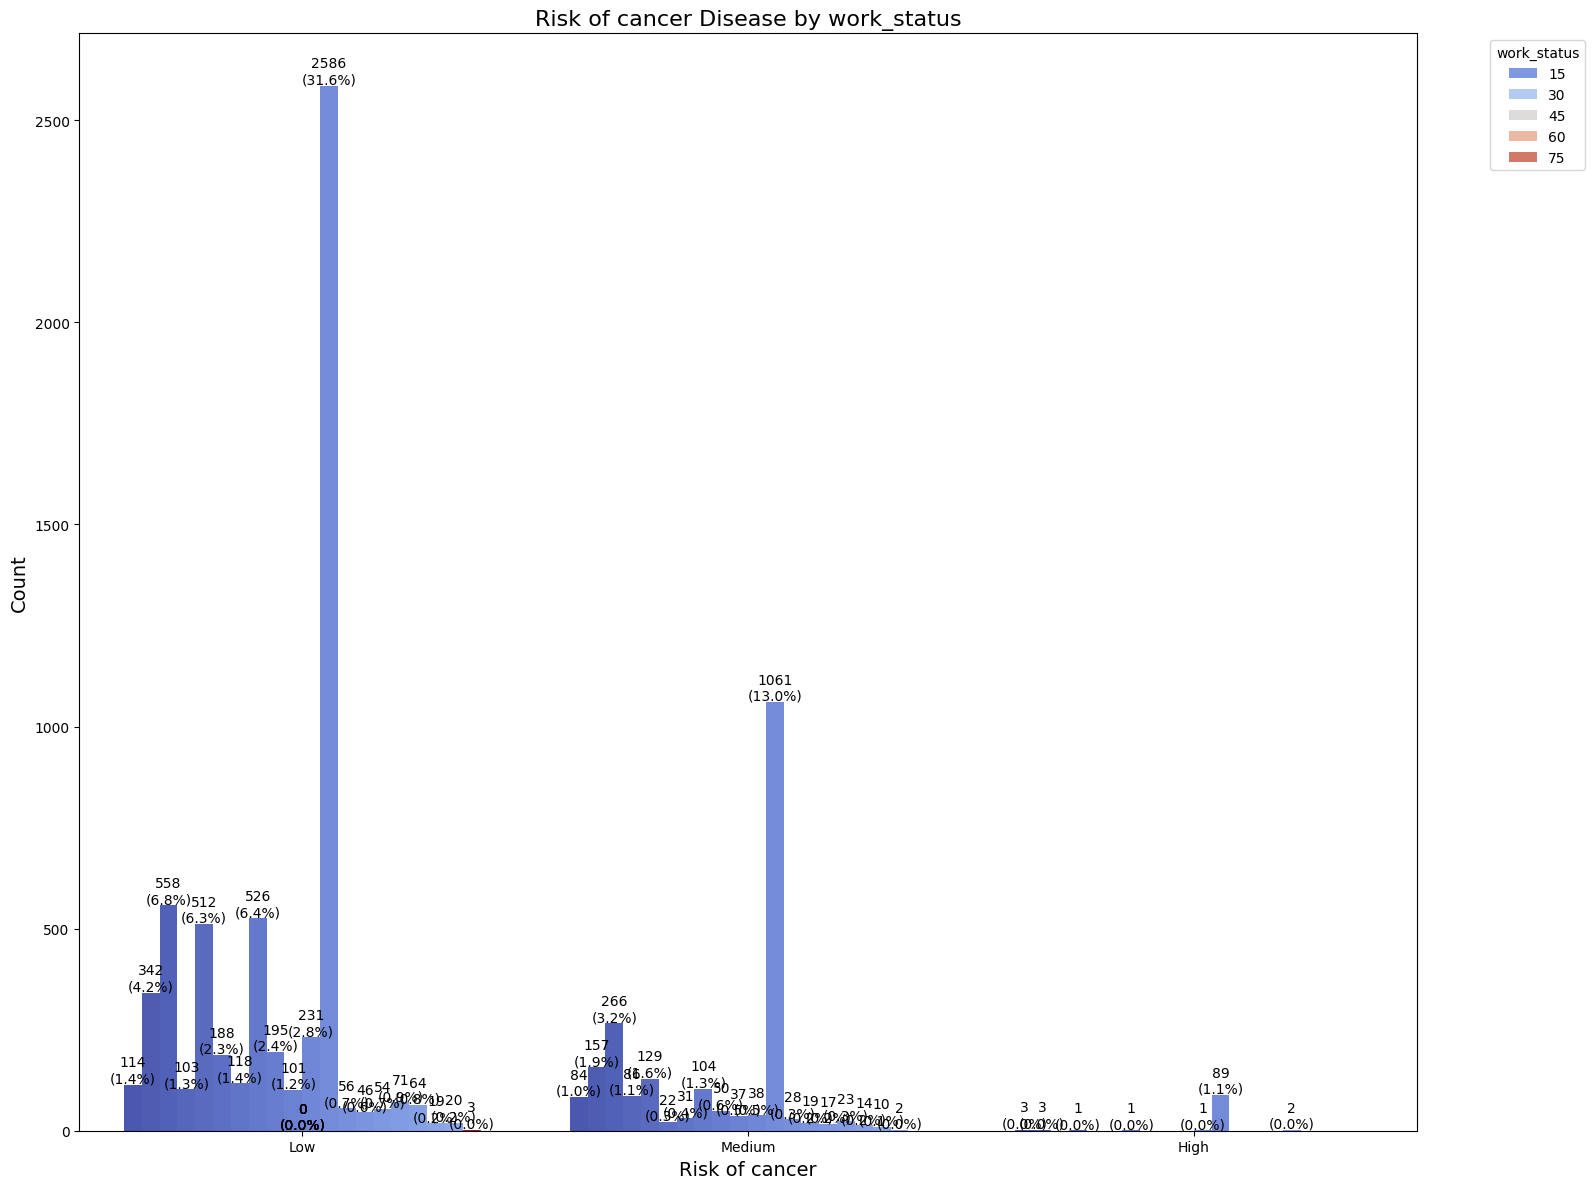

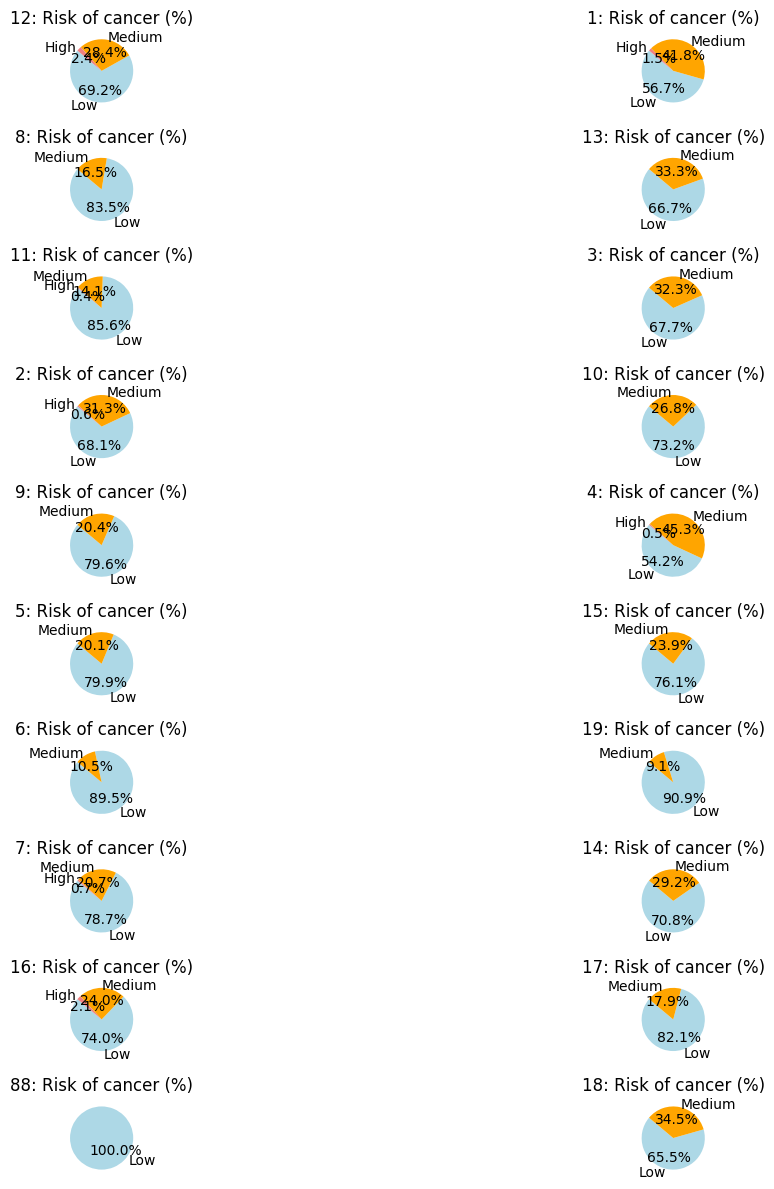

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across work_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of cancer', hue='work_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of cancer Disease by work_status', fontsize=16)
plt.xlabel('Risk of cancer', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='work_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each work_status
work_statuss = df_ncd['work_status'].unique()
num_work_statuss = len(work_statuss)
plt.figure(figsize=(16, 12))

for idx, work_status in enumerate(work_statuss, 1):
    work_status_data = df_ncd[df_ncd['work_status'] == work_status]
    work_status_counts = work_status_data['Risk of cancer'].value_counts()

    plt.subplot((num_work_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(work_status_counts, labels=work_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{work_status}: Risk of cancer (%)')

plt.tight_layout()
plt.show()


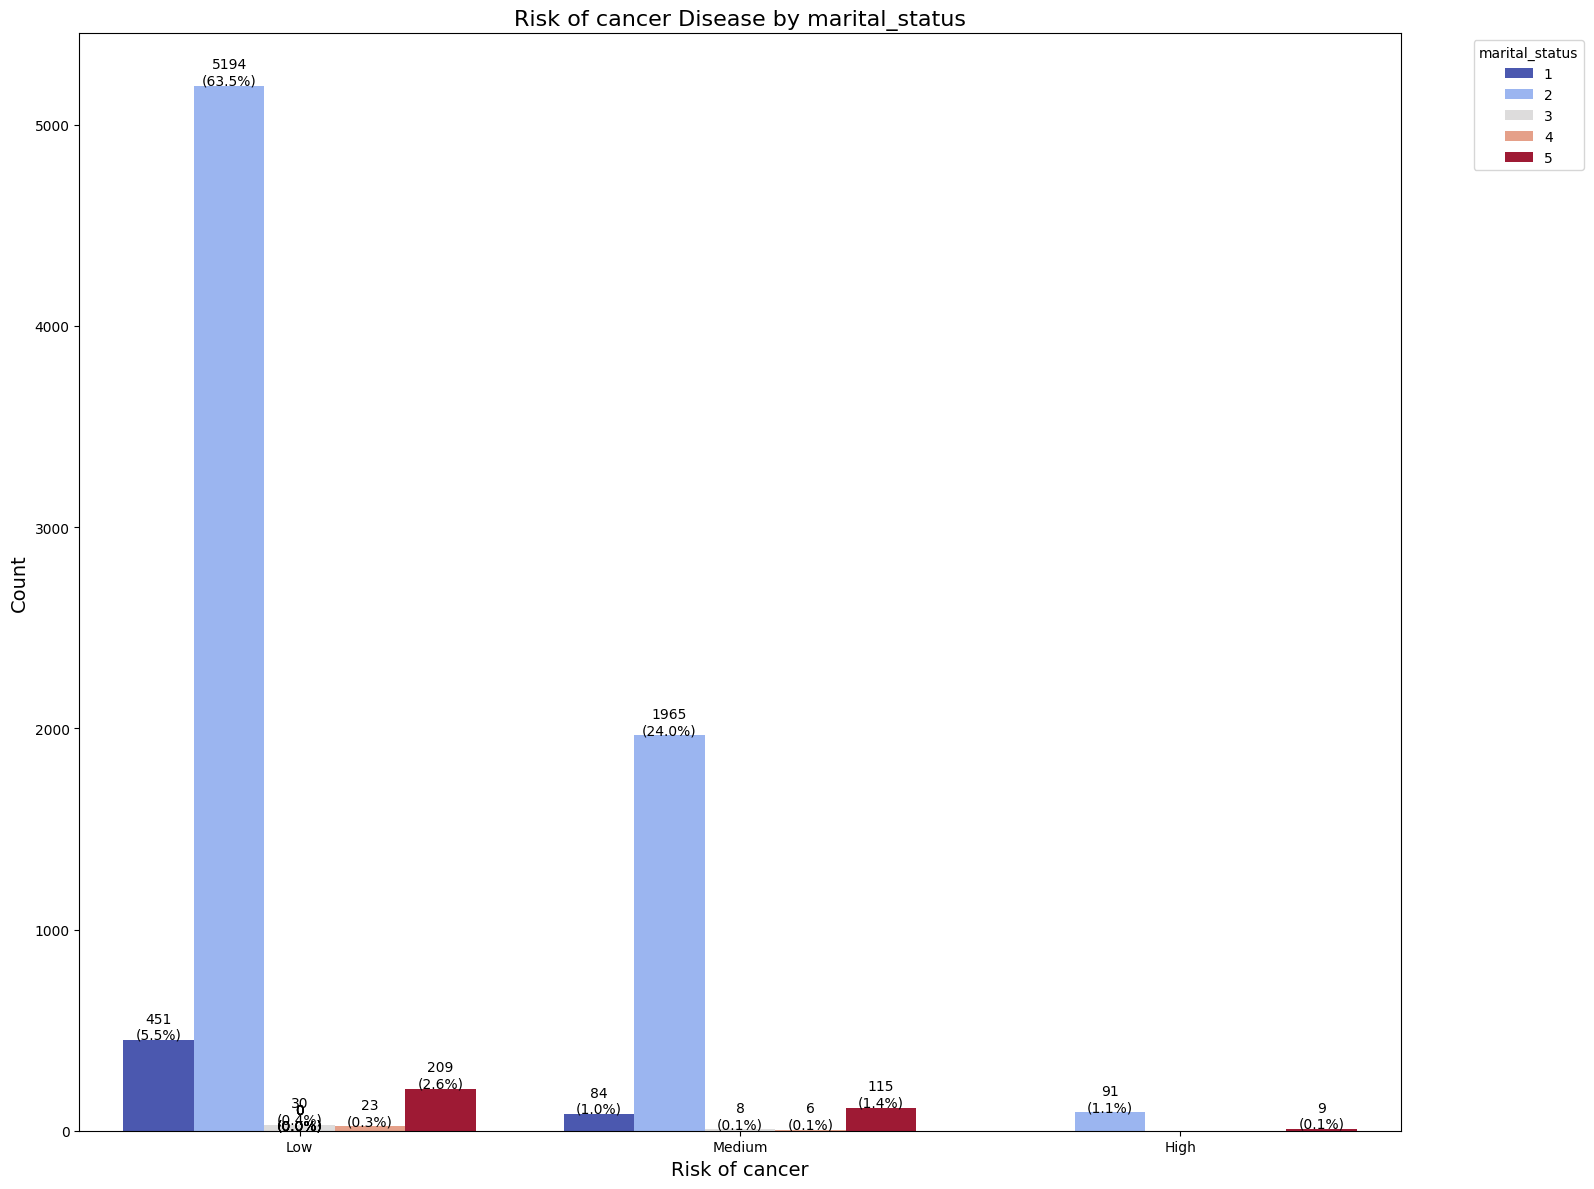

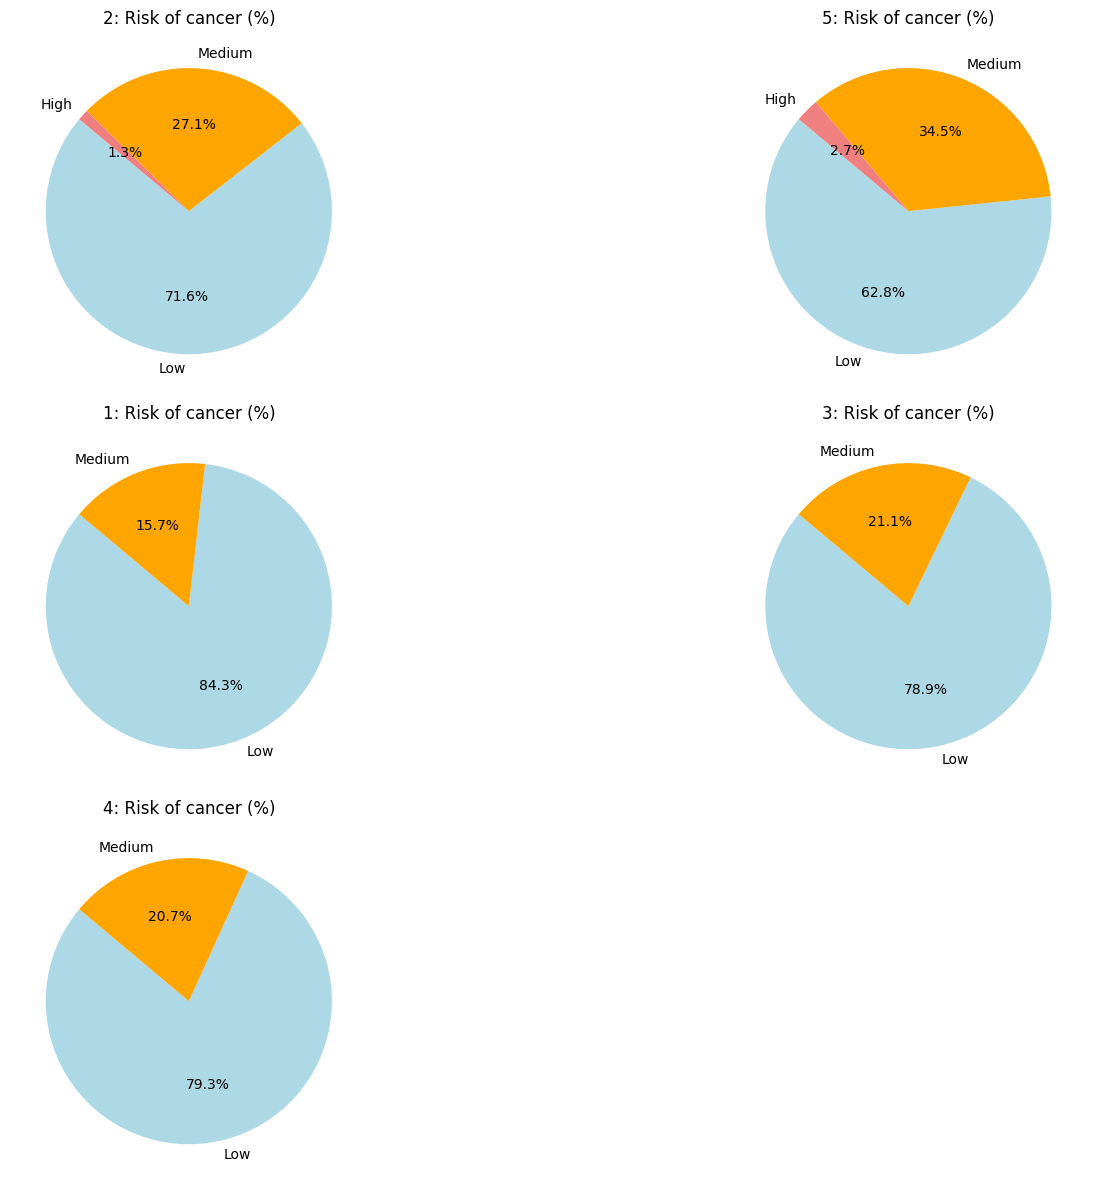

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across marital_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of cancer', hue='marital_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of cancer Disease by marital_status', fontsize=16)
plt.xlabel('Risk of cancer', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='marital_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each marital_status
marital_statuss = df_ncd['marital_status'].unique()
num_marital_statuss = len(marital_statuss)
plt.figure(figsize=(16, 12))

for idx, marital_status in enumerate(marital_statuss, 1):
    marital_status_data = df_ncd[df_ncd['marital_status'] == marital_status]
    marital_status_counts = marital_status_data['Risk of cancer'].value_counts()

    plt.subplot((num_marital_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(marital_status_counts, labels=marital_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{marital_status}: Risk of cancer (%)')

plt.tight_layout()
plt.show()


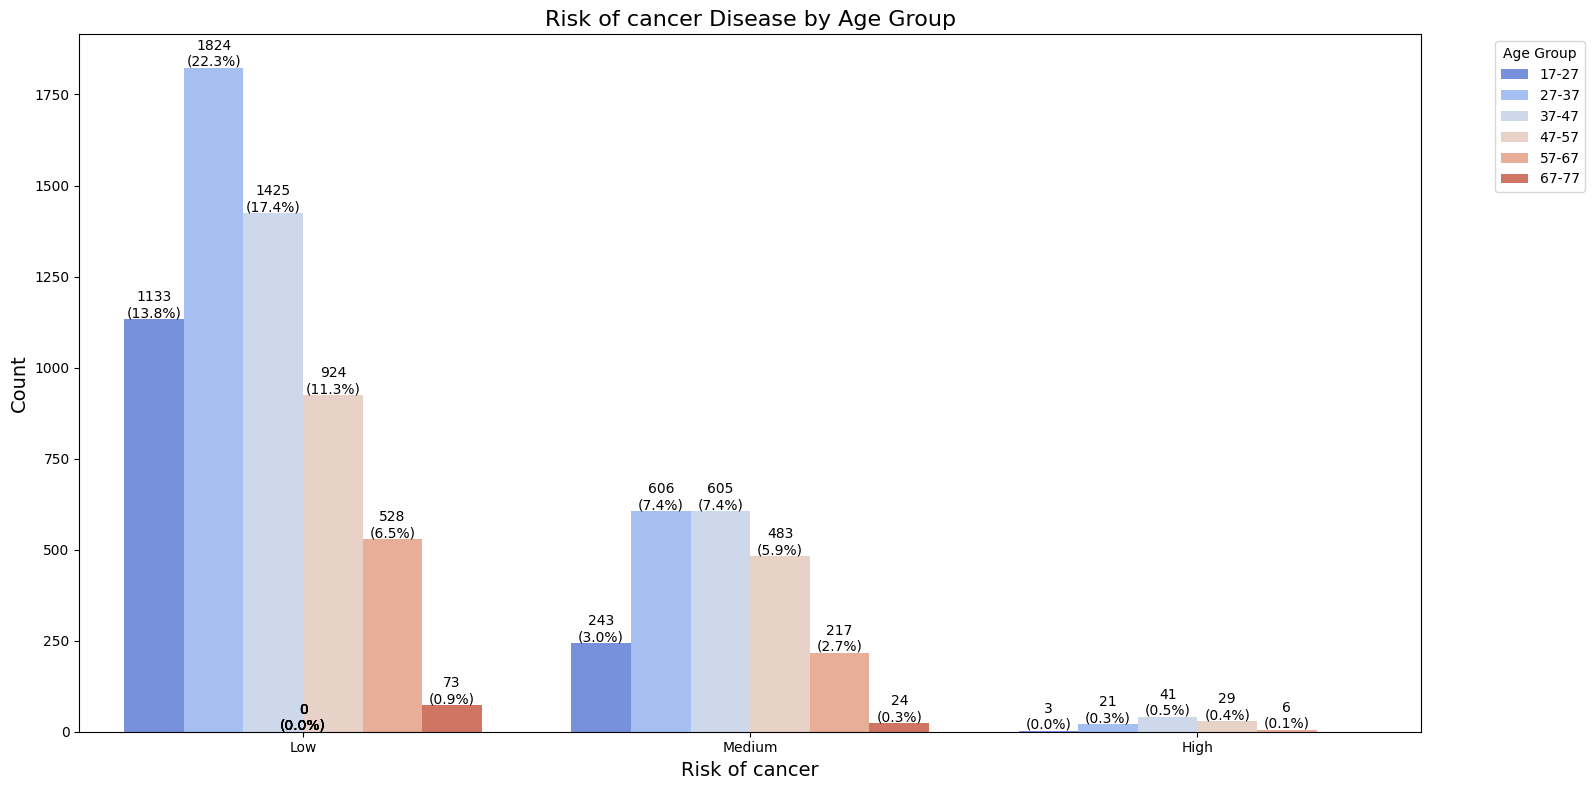

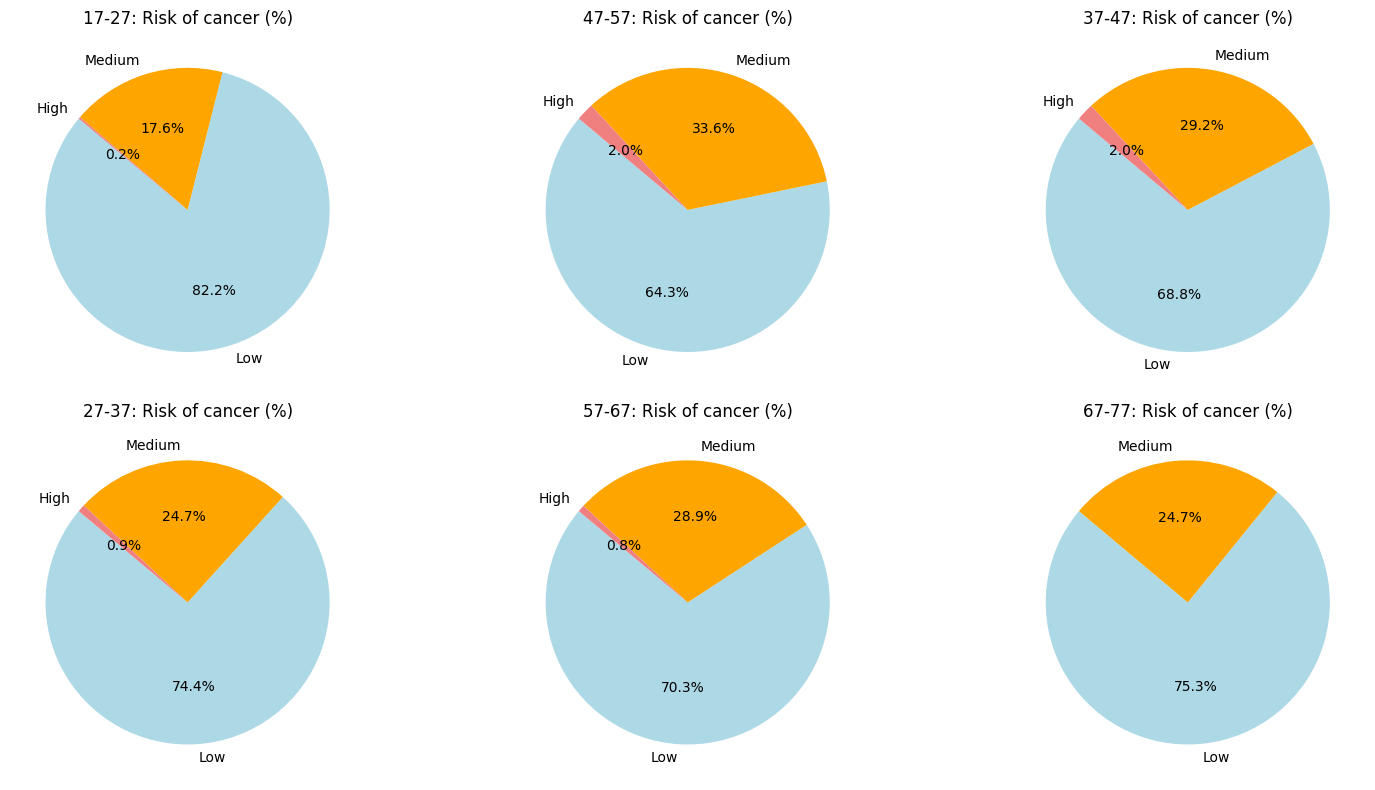

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create age groups
age_bins = [17, 27, 37, 47, 57, 67, 77]  # Age bin boundaries
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']  # Age group labels

# Add the age group column to the dataset
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Overall count plot with counts and percentages
plt.figure(figsize=(16, 8))
sns.countplot(x='Risk of cancer', hue='age_group', data=df_ncd, palette='coolwarm')
plt.title('Risk of cancer Disease by Age Group', fontsize=16)
plt.xlabel('Risk of cancer', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each age group
age_groups = df_ncd['age_group'].unique()
num_age_groups = len(age_groups)
plt.figure(figsize=(16, 8))

for idx, age_group in enumerate(age_groups, 1):
    age_group_data = df_ncd[df_ncd['age_group'] == age_group]
    age_group_counts = age_group_data['Risk of cancer'].value_counts()

    plt.subplot((num_age_groups + 2) // 3, 3, idx)  # Arrange pie charts in a grid
    plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{age_group}: Risk of cancer (%)')

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Define X (features) and y (target)
X = df_ncd[features]  # Features from clustering
y = df_ncd['Risk of cancer']  # Target variable

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# Dictionary to store models and their names
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

# Dictionary to hold evaluation results
results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)  # Train model
    y_pred = model.predict(X_test)  # Make predictions on test set

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    # Store results
    results[name] = {
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Precision': precision,
        'Recall': recall
    }
    # Print classification report for each model
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred))


Classification Report for Logistic Regression:
               precision    recall  f1-score   support

        High       1.00      1.00      1.00        18
         Low       0.95      0.98      0.96      1209
      Medium       0.92      0.86      0.89       410

    accuracy                           0.95      1637
   macro avg       0.96      0.95      0.95      1637
weighted avg       0.95      0.95      0.95      1637

Classification Report for K-Nearest Neighbors:
               precision    recall  f1-score   support

        High       0.67      0.11      0.19        18
         Low       0.94      0.98      0.96      1209
      Medium       0.94      0.85      0.89       410

    accuracy                           0.94      1637
   macro avg       0.85      0.65      0.68      1637
weighted avg       0.94      0.94      0.94      1637

Classification Report for Decision Tree:
               precision    recall  f1-score   support

        High       1.00      0.94      0.97  

In [ ]:
import pandas as pd

# Convert results to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing
print(results_df)


                        Accuracy  F1 Score  Precision  Recall
Logistic Regression        0.947     0.947      0.947   0.947
K-Nearest Neighbors        0.941     0.936      0.938   0.941
Decision Tree              0.979     0.979      0.979   0.979
Random Forest              0.985     0.985      0.985   0.985
Support Vector Machine     0.931     0.925      0.920   0.931


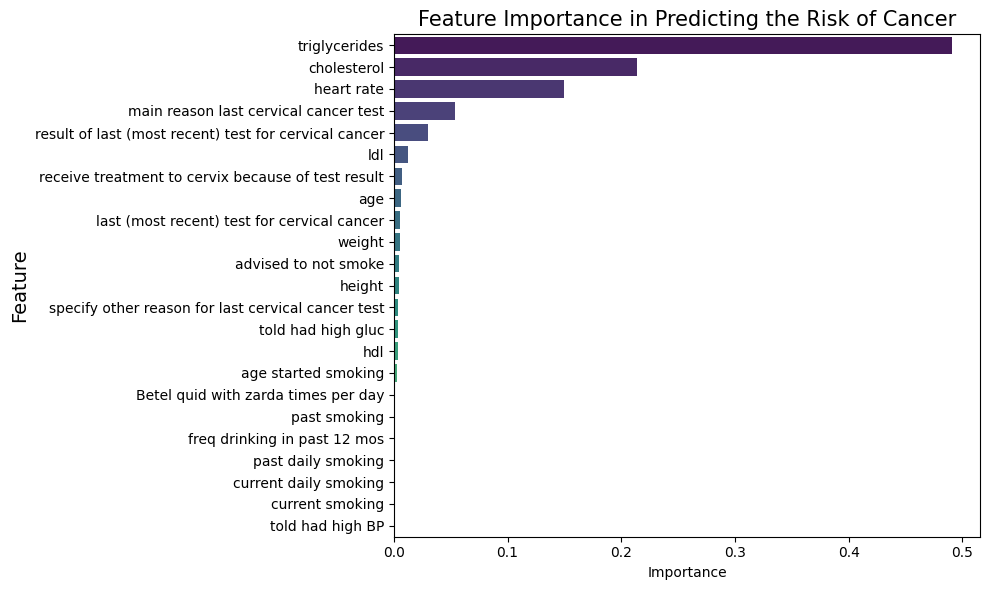

Feature Importance (sorted):
                                              Feature  Importance
20                                      triglycerides       0.491
19                                        cholesterol       0.214
18                                         heart rate       0.150
1               main reason last cervical cancer test       0.054
3   result of last (most recent) test for cervical...       0.030
22                                                ldl       0.012
4   receive treatment to cervix because of test re...       0.007
15                                                age       0.006
0         last (most recent) test for cervical cancer       0.006
17                                             weight       0.005
13                               advised to not smoke       0.005
16                                             height       0.005
2   specify other reason for last cervical cancer ...       0.004
12                                 told had hig

In [ ]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns


# Define features and target (make sure these match your dataset columns)
features = ['last (most recent) test for cervical cancer',
    'main reason last cervical cancer test',
    'specify other reason for last cervical cancer test',
    'result of last (most recent) test for cervical cancer',
    'receive treatment to cervix because of test result',
    'current smoking', 'current daily smoking', 'age started smoking',
    'past smoking', 'past daily smoking', 'freq drinking in past 12 mos',
    'told had high BP', 'told had high gluc', 'advised to not smoke', 'Betel quid with zarda times per day', 'age',
    'height', 'weight', 'heart rate', 'cholesterol', 'triglycerides', 'hdl', 'ldl']

# Separate features (X) and target variable (y)
X = df_ncd[features]  # Select features
y = df_ncd['Risk of cancer']  # Assuming 'Risk of cancer' is your target column

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a decision tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Get feature importances
importances = clf.feature_importances_

# Create a DataFrame to view feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance in Predicting the Risk of Cancer', fontsize=15)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

# Print the sorted importance values
print("Feature Importance (sorted):")
print(importance_df)


In [ ]:
#Smote

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder

# Encode the 'Risk of cancer' categories to integers
le = LabelEncoder()
df_ncd['Risk of cancer Encoded'] = le.fit_transform(df_ncd['Risk of cancer'])

# Separate features and target
X = df_ncd[selected_features]
y = df_ncd['Risk of cancer Encoded']

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Decode the target back to the original categories
y_resampled_decoded = le.inverse_transform(y_resampled)

# Create a new DataFrame with the resampled data
df_resampled = pd.DataFrame(X_resampled, columns=selected_features)
df_resampled['Risk of cancer'] = y_resampled_decoded

# Check the distribution of the target variable after SMOTE
print("Distribution of 'Risk of cancer' after SMOTE:")
print(df_resampled['Risk of cancer'].value_counts())


Distribution of 'Risk of cancer' after SMOTE:
Risk of cancer
Low       5907
Medium    5907
High      5907
Name: count, dtype: int64


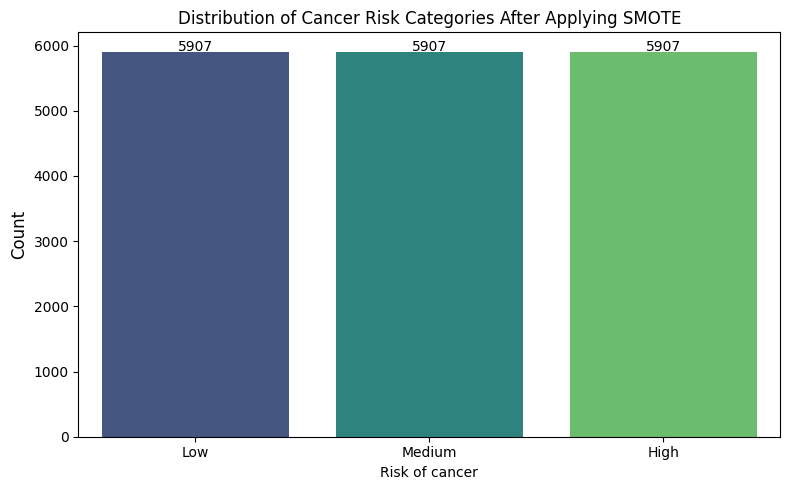

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category after SMOTE
risk_counts = df_resampled['Risk of cancer'].value_counts()

# Plot the bar graph
plt.figure(figsize=(8, 5))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='viridis')

# Add titles and labels
plt.title('Distribution of Cancer Risk Categories After Applying SMOTE', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Show values on top of the bars
for i, value in enumerate(risk_counts.values):
    plt.text(i, value + 5, str(value), ha='center', fontsize=10)

# Display the plot
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Prepare the data
X = df_resampled[selected_features]
y = df_resampled['Risk of cancer']

# Encode the target variable (if not already encoded)
y_encoded = le.fit_transform(y)  # Using the same LabelEncoder as before

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

# Initialize dictionary to store results
results = {}

# Train and evaluate each model
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Get classification metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    # Extract Precision, Recall, F1-Score for each model class
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Store results in the dictionary
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1_score,
        'Confusion Matrix': confusion_matrix(y_test, y_pred)
    }

# Convert results dictionary to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing

# Print results
print(results_df)


                       Accuracy Precision Recall F1-Score  \
Logistic Regression       0.992     0.992  0.992    0.992   
Random Forest             0.994     0.994  0.994    0.994   
Support Vector Machine    0.935     0.935  0.935    0.935   
Decision Tree             0.992     0.992  0.992    0.992   
K-Nearest Neighbors       0.974     0.974  0.974    0.974   

                                                      Confusion Matrix  
Logistic Regression       [[1181, 0, 0], [1, 1167, 14], [1, 13, 1168]]  
Random Forest             [[1180, 0, 1], [0, 1171, 11], [0, 10, 1172]]  
Support Vector Machine  [[1166, 0, 15], [2, 1106, 74], [66, 72, 1044]]  
Decision Tree             [[1180, 0, 1], [0, 1170, 12], [0, 17, 1165]]  
K-Nearest Neighbors     [[1164, 0, 17], [1, 1150, 31], [18, 24, 1140]]  


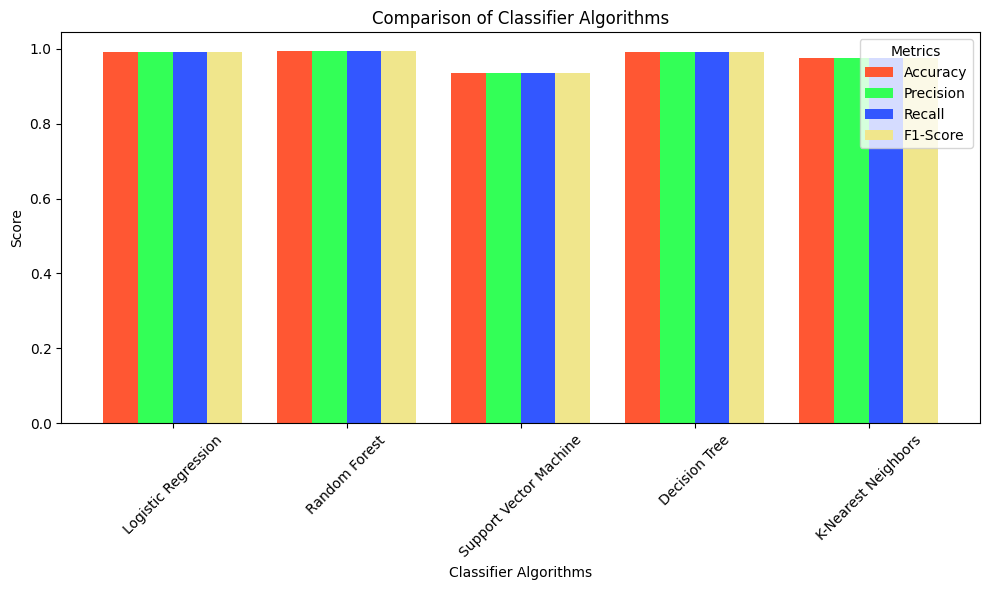

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare the data
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Create a DataFrame from the results for easier plotting
metrics_df = results_df[metrics]

# Define colors for each metric
colors = ['#FF5733', '#33FF57', '#3357FF', '#F0E68C']

# Plot the comparison of classifiers using bar graphs with different colors for each metric
plt.figure(figsize=(10, 6))

# Loop through each metric and plot its bars with different colors
bar_width = 0.2  # Set the width of the bars
index = np.arange(len(metrics_df))  # Position for each classifier

for i, metric in enumerate(metrics):
    plt.bar(index + i * bar_width, metrics_df[metric], bar_width, label=metric, color=colors[i])

# Add labels and title
plt.xlabel('Classifier Algorithms')
plt.ylabel('Score')
plt.title('Comparison of Classifier Algorithms')

# Adjust x-ticks to be centered and show classifier names
plt.xticks(index + bar_width * 1.5, metrics_df.index, rotation=45)

# Add legend
plt.legend(title='Metrics')

# Tight layout to prevent overlapping labels
plt.tight_layout()

# Show plot
plt.show()


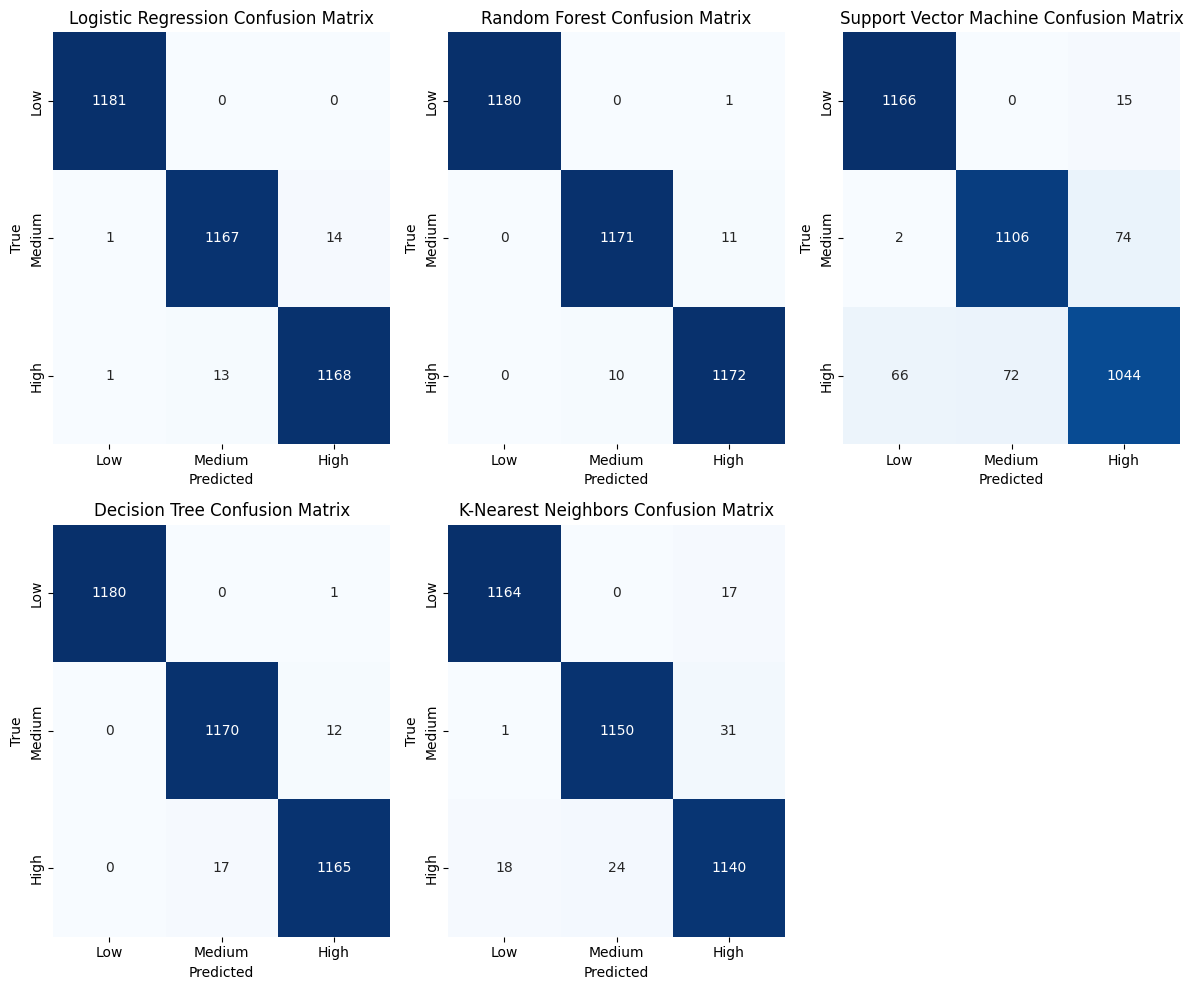

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot the confusion matrix for each model
plt.figure(figsize=(12, 10))

# Iterate through models and plot their confusion matrix
for i, (model_name, result) in enumerate(results.items()):
    cm = result['Confusion Matrix']

    plt.subplot(2, 3, i + 1)  # Create subplots (2 rows, 3 columns)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
    plt.title(f'{model_name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')

plt.tight_layout()
plt.show()


In [ ]:
#GridSearch

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Define models and hyperparameter grids for GridSearchCV
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

param_grids = {
    'Random Forest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'bootstrap': [True, False]
    },
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear'],
        'penalty': ['l2']
    },
    'Support Vector Machine': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    },
    'Decision Tree': {
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'K-Nearest Neighbors': {
        'n_neighbors': [3, 5, 7, 10],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }
}

# Hyperparameter tuning with GridSearchCV
best_models_grid = {}

for model_name, model in models.items():
    print(f"Performing GridSearchCV for {model_name}...")

    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=5, n_jobs=-1, verbose=1)
    grid_search.fit(X_train, y_train)

    best_models_grid[model_name] = grid_search.best_estimator_
    print(f"Best parameters for {model_name}: {grid_search.best_params_}\n")

# Evaluate the best models
for model_name, model in best_models_grid.items():
    print(f"Evaluating {model_name} after GridSearchCV...")
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\n")


Performing GridSearchCV for Random Forest...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters for Random Forest: {'bootstrap': False, 'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}

Performing GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters for Logistic Regression: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}

Performing GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Support Vector Machine: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}

Performing GridSearchCV for Decision Tree...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Decision Tree: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

Performing GridSearchCV for K-Nearest Neighbors...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters for K-N